# What carries from the Combine to the game?

**A receiver movement study with matched conventional baselines, player-held-out validation, and negative controls.** Detailed tracking can describe an athlete beautifully without improving scouting predictions. We ask whether sprint response signatures contain information beyond ordinary Combine measurements, and distinguish that question from forecasting a receiver after observing the beginning of an NFL route.

This is an exploratory continuation. Earlier experiments already inspected the 2025 WR class; this notebook does not create a fresh blind test. Its reconstructed implementation strictly excludes nonunique snap/release events, retaining one fewer 2023 route than the earlier lost implementation. Historical aggregate outputs remain a separate record and are not silently substituted for this execution. The cells below recompute every result from the supplied official data. No synthetic data are used for scientific findings.


In [1]:
import os, sys, json, hashlib, tempfile, contextlib
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display, Image, HTML
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
DATA = Path(os.environ.get('BDB_DATA_ROOT','/kaggle/input/nfl-big-data-bowl-2027'))
if not (DATA/'players.csv').exists():
    candidates = list(Path('/kaggle/input').rglob('players.csv')) if Path('/kaggle/input').exists() else []
    if len(candidates)!=1: raise FileNotFoundError('Attach the official competition dataset or set BDB_DATA_ROOT.')
    DATA=candidates[0].parent
OUT=Path(tempfile.mkdtemp(prefix='bdb_movement_private_'))
SRC=OUT/'sources'; SRC.mkdir()
MODULES={'analysis.py': '"""Combine-to-game research. No competition data are bundled or fabricated."""\nfrom pathlib import Path\nimport json, hashlib, argparse, platform\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nSEED=20271006\nBASE=[\'combine_height\',\'combine_weight\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\']\nCONTEXT=[\'cushion\',\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\']\nCATS=[\'route_ran\',\'team_coverage_man_zone\',\'offense_formation\',\'in_motion_at_ball_snap\']\nMOTION=[\'entry_speed\',\'speed_retention\',\'exit_gain\',\'braking_impulse\',\'turn_angle\',\'curvature_energy\',\'jerk_rms\',\'signature_area\']\nCUT_ROUTES={\'OUT\',\'SLANT\',\'POST\',\'CORNER\',\'HITCH\'}\n\ndef movement(g,window=7):\n    """Largest interior heading change; fixed +/-0.5s event window, yards/seconds."""\n    g=g.sort_values(\'time\').copy()\n    t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    if len(t)<21 or np.any(np.diff(t)<=0): raise ValueError(\'short or duplicate/nonmonotone trajectory\')\n    dt=np.diff(t)\n    if not np.allclose(dt,.1,atol=.015): raise ValueError(\'irregular sampling; do not interpolate missing cuts\')\n    p=g[[\'x\',\'y\']].to_numpy(float)\n    if not np.isfinite(p).all(): raise ValueError(\'nonfinite coordinates\')\n    p=savgol_filter(p,window,3,axis=0)\n    v=np.gradient(p,.1,axis=0);a=np.gradient(v,.1,axis=0)\n    speed=np.linalg.norm(v,axis=1)\n    theta=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    k=np.arange(5,len(p)-5)\n    score=np.abs(theta[k+3]-theta[k-3]);score[(speed[k-3]<1)|(speed[k+3]<1)]=0\n    if score.max()<np.deg2rad(25): raise ValueError(\'no qualifying turn\')\n    c=int(k[np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-10))[0]]);sl=slice(c-5,c+6)\n    turn=theta[c+3]-theta[c-3]\n    tangent=v[c-3]/speed[c-3];normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-5])@np.stack([tangent,normal],axis=1)\n    q[:,1]*=1 if turn>=0 else -1\n    # Antisymmetric level-two path signature, equal to signed area with closing chord.\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])\n    sp=speed[sl];at=np.gradient(sp,.1)\n    omega=np.gradient(theta,.1)[sl];curv=omega/np.maximum(sp,1)\n    out=dict(entry_speed=float(np.mean(sp[:3])),speed_retention=float(sp.min()/np.mean(sp[:3])),\n      exit_gain=float(np.mean(sp[-3:])-sp.min()),braking_impulse=float(np.trapezoid(np.maximum(-at,0),dx=.1)),\n      turn_angle=float(abs(turn)),curvature_energy=float(np.trapezoid(curv**2*sp,dx=.1)),\n      jerk_rms=float(np.sqrt(np.mean(np.gradient(a[sl],.1,axis=0)**2))),signature_area=float(area))\n    diag={\'t\':np.arange(-5,6)*.1,\'q\':q,\'speed\':sp,\'tangential_acceleration\':at,\'cut_index\':c}\n    return out,diag\n\ndef inventory(root):\n    """Stream all CSVs; retain observed counts/schema/hash, never treat descriptions as measured counts."""\n    rows=[]\n    for p in sorted(Path(root).glob(\'*.csv\')):\n        count=0;ids=set();years=set();cols=None\n        for c in pd.read_csv(p,chunksize=200000):\n            count+=len(c);cols=list(c.columns)\n            if \'nfl_id\' in c: ids.update(c.nfl_id.dropna().astype(int))\n            for key in (\'season\',\'draft_year\'):\n                if key in c:years.update(c[key].dropna().astype(int))\n        h=hashlib.sha256()\n        with p.open(\'rb\') as f:\n            for b in iter(lambda:f.read(8*1024*1024),b\'\'): h.update(b)\n        rows.append(dict(file=p.name,rows=count,unique_players=len(ids),years=sorted(years),columns=cols,sha256=h.hexdigest()))\n    return rows\n\ndef prepare(root,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(root/\'players.csv\');combine=pd.read_csv(root/\'combine_results.csv\');games=pd.read_csv(root/\'games.csv\')\n    for d,key in [(players,[\'nfl_id\']),(combine,[\'nfl_id\',\'draft_year\']),(games,[\'game_id\'])]:\n        if d.duplicated(key).any():raise ValueError(\'duplicate metadata join key\')\n    ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);pieces=[]\n    drill_counts={}\n    for c in pd.read_csv(root/\'combine_tracking.csv\',chunksize=200000):\n        c=c[c.nfl_id.isin(ids)&c.entity_type.eq(\'PLAYER\')&c.drill_type.eq(\'SKILL_DRILLS_WR\')]\n        pieces.append(c)\n        for name,n in c.drill_name.value_counts().items():drill_counts[name]=drill_counts.get(name,0)+int(n)\n    track=pd.concat(pieces,ignore_index=True);features=[];rejects=[]\n    for keys,g in track.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:\n            f,_=movement(g);features.append(dict(nfl_id=keys[0],draft_year=keys[1],event_id=keys[2],drill_name=g.drill_name.iloc[0],**f))\n        except ValueError as e:rejects.append(dict(event_id=keys[2],reason=str(e)))\n    f=pd.DataFrame(features)\n    if f.empty:raise ValueError(\'no qualifying WR turns; inspect drill availability before changing protocol\')\n    f.to_csv(out/\'attempt_features.csv\',index=False)\n    # Choose one homologous drill using Combine availability only, before NFL outcomes.\n    availability=f.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    minimum=availability.min(axis=1);eligible=minimum[minimum>=5]\n    if eligible.empty:raise ValueError(\'no qualifying drill shared by >=5 WRs in every class; inspect availability\')\n    selected=sorted(eligible.index,key=lambda k:(-eligible[k],k))[0]\n    f=f[f.drill_name.eq(selected)]\n    agg=f.groupby([\'nfl_id\',\'draft_year\'])[MOTION].median().reset_index()\n    pp=pd.read_csv(root/\'player_play.csv\')\n    if pp.duplicated([\'game_id\',\'play_id\',\'nfl_id\']).any():raise ValueError(\'duplicate player-play key\')\n    pp=pp.merge(games[[\'game_id\',\'season\',\'season_type\']],on=\'game_id\',validate=\'many_to_one\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    d=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(CUT_ROUTES)&pp.play_nullified_by_penalty.eq(\'N\')].copy()\n    d=d[np.isfinite(d.separation_at_pass_forward)&(d.separation_at_pass_forward>=0)]\n    d=d.merge(combine,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    # Each player must have >=20 measured routes. Threshold is frozen before labels are inspected.\n    n=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(n[n>=20].index)]\n    audit={\'status\':\'actual_data_prepared\',\'draft_class_players\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\n      \'draft_class_routes\':d.groupby(\'draft_year\').size().to_dict(),\'wr_roster_players\':len(ids),\'qualifying_attempts\':len(f),\n      \'selected_drill\':selected,\'drill_player_availability\':availability.to_dict(),\'excluded_attempts\':rejects,\'drill_frame_counts\':drill_counts,\'target_only_fraction\':float(d.target.mean()) if len(d) else None,\n      \'game_tracking_use\':\'Primary outcome uses official separation; game trajectory replication remains secondary and unrun.\'}\n    temp=out/\'private_analysis_rows.csv.tmp\';d.to_csv(temp,index=False);temp.replace(out/\'private_analysis_rows.csv\');\n    if len(pd.read_csv(out/\'private_analysis_rows.csv\'))!=len(d):raise ValueError(\'analysis CSV roundtrip row mismatch\')\n    d.to_pickle(out/\'private_analysis_rows.pkl\');(out/\'population_audit.json\').write_text(json.dumps(audit,indent=2))\n    return d,f,audit\n\ndef model(d,nums,kind,alpha=10):\n    numeric=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n    cats=Pipeline([(\'impute\',SimpleImputer(strategy=\'most_frequent\')),(\'onehot\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))])\n    pre=ColumnTransformer([(\'numeric\',numeric,nums),(\'category\',cats,CATS)])\n    reg=Ridge(alpha=alpha) if kind==\'ridge\' else RandomForestRegressor(n_estimators=200,min_samples_leaf=20,max_depth=6,max_features=.8,random_state=SEED,n_jobs=2)\n    return Pipeline([(\'pre\',pre),(\'reg\',reg)])\n\ndef weights(d):return 1/d.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy()\ndef score(d,p):return float(np.average((d.separation_at_pass_forward.to_numpy()-p)**2,weights=weights(d)))\n\ndef compare(d,out):\n    """Player-disjoint, rookie-season-disjoint validation and locked 2025 test."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);d=d.copy()\n    if not (d.season==d.draft_year).all():raise ValueError(\'rookie seasons required\')\n    for col in MOTION:\n        d[col+\'_mass\']=d[col]*d.combine_weight/200\n        d[col+\'_man\']=d[col]*d.team_coverage_man_zone.eq(\'MAN_COVERAGE\').astype(int)\n    families={\'conventional\':BASE+CONTEXT,\'tracking\':BASE+CONTEXT+MOTION,\n      \'physical_context_interactions\':BASE+CONTEXT+MOTION+[c+s for c in MOTION for s in (\'_mass\',\'_man\')],\n      \'scouting_reference\':BASE+CONTEXT+[\'ngs_college_production_score\']}\n    a,b,t=[d[d.draft_year.eq(y)] for y in (2023,2024,2025)]\n    if min(x.nfl_id.nunique() for x in (a,b,t))<10:raise ValueError(\'fewer than ten WRs in a class; insufficient locked-cohort study\')\n    assert not(set(a.nfl_id)&set(b.nfl_id) or set(a.nfl_id)&set(t.nfl_id) or set(b.nfl_id)&set(t.nfl_id))\n    dev=pd.concat([a,b]);results=[];pred={};selections={}\n    for kind in (\'ridge\',\'forest\'):\n      for family,nums in families.items():\n        options=(1,10,100) if kind==\'ridge\' else (10,)\n        vals=[]\n        for alpha in options:\n            m=model(a,nums,kind,alpha);m.fit(a,a.separation_at_pass_forward,reg__sample_weight=weights(a));vals.append((score(b,m.predict(b)),alpha))\n        _,alpha=min(vals);selections[kind+\'_\'+family]={\'alpha\':alpha,\'validation_mse\':min(vals)[0]}\n        m=model(dev,nums,kind,alpha);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=weights(dev));p=m.predict(t)\n        name=kind+\'_\'+family;pred[name]=p\n        results.append({\'model\':name,\'test_player_balanced_mse\':score(t,p),\'test_rmse_yards\':score(t,p)**.5,\'validation_mse\':min(vals)[0]})\n    # Primary contrast is ridge tracking vs ridge conventional. Others exploratory.\n    losses=pd.DataFrame({\'nfl_id\':t.nfl_id,\'baseline\':(t.separation_at_pass_forward-pred[\'ridge_conventional\'])**2,\'tracking\':(t.separation_at_pass_forward-pred[\'ridge_tracking\'])**2}).groupby(\'nfl_id\').mean()\n    delta=(losses.baseline-losses.tracking).to_numpy();rng=np.random.default_rng(SEED)\n    boots=np.mean(rng.choice(delta,(5000,len(delta)),replace=True),axis=1)\n    report={\'status\':\'actual_data_completed\',\'primary_delta_mse_yards_squared\':float(delta.mean()),\'player_bootstrap_ci95\':np.quantile(boots,[.025,.975]).tolist(),\n      \'test_players\':len(delta),\'test_routes\':len(t),\'results\':results,\'selection\':selections,\n      \'interpretation\':\'positive delta favors motion; CI crossing zero is inconclusive; cohort-generalization requires more years\',\n      \'selection_warning\':\'Exploratory models cannot replace the preregistered primary contrast after observing test labels.\'}\n    pd.DataFrame(results).to_csv(out/\'model_comparisons.csv\',index=False)\n    (out/\'experiment_results.json\').write_text(json.dumps(report,indent=2))\n    pp=t[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in pred.items():pp[k]=v\n    pp.to_csv(out/\'private_test_predictions.csv\',index=False)\n    return report\n\ndef plot_motion(diag,path,label):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'text.color\':\'#e6edf6\',\'axes.labelcolor\':\'#c2cfde\',\'xtick.color\':\'#8aa0b6\',\'ytick.color\':\'#8aa0b6\',\'axes.edgecolor\':\'#304359\',\'axes.facecolor\':\'#102236\',\'figure.facecolor\':\'#071421\'})\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');q=diag[\'q\'];t=diag[\'t\'];s=diag[\'speed\'];a=diag[\'tangential_acceleration\']\n    sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'plasma\',s=80,zorder=3);ax[0].plot(q[:,0],q[:,1],color=\'#39dbbd\',alpha=.8);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Along entry direction · yards\',ylabel=\'Across entry direction · yards\',title=\'THE SHAPE OF THE CUT\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\',shrink=.7)\n    ax[1].plot(t,s,lw=3,color=\'#39dbbd\');ax[1].axvline(0,color=\'#efb455\',ls=\':\');ax[1].set(xlabel=\'Seconds from largest turn\',ylabel=\'Speed · yd/s\',title=\'BRAKE → TURN → RECOVER\')\n    ax[2].plot(s,a,lw=2,color=\'#efb455\');ax[2].scatter(s,a,c=t,cmap=\'cool\',s=40);ax[2].axhline(0,color=\'#304359\');ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Tangential acceleration · yd/s²\',title=\'MOVEMENT PHASE PORTRAIT\')\n    for z in ax:z.grid(alpha=.12)\n    fig.suptitle(label,fontsize=17,fontweight=\'bold\');fig.savefig(path,dpi=150);plt.close(fig)\n\ndef run(root,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    (out/\'inventory.json\').write_text(json.dumps(inventory(root),indent=2))\n    d,f,audit=prepare(root,out);report=compare(d,out)\n    # Selected example by sorted ID, independent of outcomes. Read only WR tracking rows.\n    chosen=f.sort_values([\'nfl_id\',\'event_id\']).iloc[0];parts=[]\n    for c in pd.read_csv(Path(root)/\'combine_tracking.csv\',chunksize=200000):parts.append(c[c.event_id.eq(chosen.event_id)&c.entity_type.eq(\'PLAYER\')])\n    g=pd.concat(parts);_,diag=movement(g);plot_motion(diag,out/\'actual_combine_geometry.png\',\'Observed Combine trajectory · selected without NFL outcomes\')\n    (out/\'actual_combine_geometry.html\').write_text(motion_html(diag,\'Observed Combine attempt · selected independently of NFL outcomes\'))\n    return report\n\n\ndef game_transfer(root,d,out):\n    """Secondary descriptive mechanics replication; game motion never a prospect predictor."""\n    out=Path(out);pieces=[];ids=set(d.nfl_id)\n    keys=d[[\'game_id\',\'play_id\',\'nfl_id\']].drop_duplicates()\n    for year in (2023,2024,2025):\n        p=Path(root)/f\'game_tracking_{year}.csv\';parts=[]\n        for c in pd.read_csv(p,chunksize=200000):\n            c=c[c.nfl_id.isin(ids)].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],how=\'inner\',validate=\'many_to_one\');parts.append(c)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\']):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if snap.empty or release.empty:continue\n            g=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:\n                f,_=movement(g);pieces.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            except ValueError:continue\n    pd.DataFrame(pieces).to_csv(out/\'private_game_motion.csv\',index=False)\n    return {\'status\':\'descriptive_only\',\'qualifying_game_turns\':len(pieces),\'note\':\'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.\'}\n\ndef motion_html(diag,label):\n    """Offline SVG animation of measured samples, not a generated football replay."""\n    import html\n    data=json.dumps({k:diag[k].tolist() for k in (\'t\',\'q\',\'speed\',\'tangential_acceleration\')})\n    template=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Inside the cut</title><style>\nbody{background:#071421;color:#e6edf6;font:17px system-ui;margin:0;padding:4vw}main{max-width:1000px;margin:auto}.tag{color:#39dbbd;font-size:12px;letter-spacing:2px}h1{font-size:clamp(28px,5vw,52px)}.layout{display:grid;grid-template-columns:2fr 1fr;gap:24px}svg{background:#102236;width:100%;border-radius:20px}button{background:#39dbbd;color:#071421;border:0;border-radius:9px;padding:12px 22px;font-weight:700}input{width:100%;accent-color:#39dbbd}small{color:#9cafc3}strong{font-size:40px;display:block}.metric{margin:22px 0}@media(max-width:650px){.layout{grid-template-columns:1fr}} </style>\n<main><div class="tag">MOVEMENT LAB · FRAME BY FRAME</div><h1>Inside the cut.</h1><p>LABEL</p><div class="layout"><svg id="field" viewBox="0 0 600 400" role="img" aria-label="Canonical trajectory in yards"><g id="grid"></g><path id="path" fill="none" stroke="#39dbbd" stroke-width="3"/><g id="samples"></g><circle id="player" r="12" fill="#efb455" stroke="#071421" stroke-width="4"/><text x="22" y="380" fill="#9cafc3" font-size="14">Canonical entry frame · yards</text></svg><aside><div class="metric">Time from detected turn<strong id="time"></strong><small>seconds</small></div><div class="metric">Speed<strong id="speed"></strong><small>yards / second</small></div><div class="metric">Braking / reacceleration<strong id="acc"></strong><small>yards / second²</small></div></aside></div><p><button id="play">Play movement</button> <small>Eleven observed samples; interpolation animates the marker only.</small></p><input id="frame" type="range" min="0" max="10" step=".01" value="0" aria-label="Inspect tracking moment"><p><small>The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.</small></p></main>\n<script>const D=DATA;const ns=\'http://www.w3.org/2000/svg\';const xs=D.q.map(p=>p[0]),ys=D.q.map(p=>p[1]);let xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys);const scale=Math.min(500/Math.max(xmax-xmin,.2),280/Math.max(ymax-ymin,.2));const P=D.q.map(p=>[50+(p[0]-xmin)*scale,330-(p[1]-ymin)*scale]);function node(tag,attrs,parent){let e=document.createElementNS(ns,tag);for(let k in attrs)e.setAttribute(k,attrs[k]);parent.appendChild(e);return e}for(let x=Math.floor(xmin);x<=xmax;x++){const z=50+(x-xmin)*scale;node(\'line\',{x1:z,y1:20,x2:z,y2:350,stroke:\'#233c51\'},document.querySelector(\'#grid\'));const t=node(\'text\',{x:z,y:365,fill:\'#9cafc3\',\'font-size\':12},document.querySelector(\'#grid\'));t.textContent=x;}document.querySelector(\'#path\').setAttribute(\'d\',P.map((p,i)=>(i?\'L\':\'M\')+p.join(\',\')).join(\' \'));let low=Math.min(...D.speed),high=Math.max(...D.speed);P.forEach((p,i)=>node(\'circle\',{cx:p[0],cy:p[1],r:5,fill:`hsl(${180-140*(D.speed[i]-low)/Math.max(high-low,.01)} 75% 60%)`},document.querySelector(\'#samples\')));let f=document.querySelector(\'#frame\'),playing=false,last=0;function show(){let z=+f.value,i=Math.min(9,Math.floor(z)),a=z-i;let p=P[i].map((v,k)=>v+(P[i+1][k]-v)*a);document.querySelector(\'#player\').setAttribute(\'cx\',p[0]);document.querySelector(\'#player\').setAttribute(\'cy\',p[1]);for(let [id,key] of [[\'time\',\'t\'],[\'speed\',\'speed\'],[\'acc\',\'tangential_acceleration\']])document.querySelector(\'#\'+id).textContent=(D[key][i]+(D[key][i+1]-D[key][i])*a).toFixed(2)}f.oninput=()=>{playing=false;document.querySelector(\'#play\').textContent=\'Play movement\';show()};document.querySelector(\'#play\').onclick=()=>{playing=!playing;if(+f.value>=10)f.value=0;document.querySelector(\'#play\').textContent=playing?\'Pause\':\'Play movement\';last=performance.now()};function tick(now){if(playing){f.value=Math.min(10,+f.value+(now-last)/300);show();if(+f.value>=10){playing=false;document.querySelector(\'#play\').textContent=\'Replay movement\'}}last=now;requestAnimationFrame(tick)}show();requestAnimationFrame(tick);</script>\'\'\'\n    return template.replace(\'LABEL\',html.escape(label)).replace(\'DATA\',data)\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',required=True);ap.add_argument(\'--out\',default=\'private_results\');args=ap.parse_args();print(json.dumps(run(args.data,args.out),indent=2))\n', 'repo_predict.py': '"""Prospect-balanced compression and development-only model selection.\n\n2025 was already inspected before this push; its results are exploratory.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np,pandas as pd\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A\n\nPHYS=A.BASE+[\'hand_size\',\'arm_length\',\'wing_span\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nNUM=A.CONTEXT+[\'quarter\']\nCAT=A.CATS+[\'team_coverage_type\',\'receiver_alignment\',\'team_abbr\',\'defense_team\']\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':1,\'k\':4},{\'reg\':\'ridge\',\'alpha\':10,\'k\':4},{\'reg\':\'ridge\',\'alpha\':100,\'k\':8},{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':8}]\n\nclass ProspectEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,motion=(),k=4):self.motion=motion;self.k=k\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_player_ids_=set(players.nfl_id)\n        self.phys=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.phys.fit(players[PHYS])\n        self.num=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.num.fit(x[NUM])\n        self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);self.cat.fit(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))\n        if self.motion:\n            m=players[list(self.motion)].to_numpy(float);self.lo=np.nanquantile(m,.01,axis=0);self.hi=np.nanquantile(m,.99,axis=0)\n            self.lo=np.nan_to_num(self.lo);self.hi=np.nan_to_num(self.hi)\n            self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m)\n            self.pca=PCA(n_components=min(self.k,len(players)-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m)\n        return self\n    def transform(self,x):\n        blocks=[self.phys.transform(x[PHYS]),self.num.transform(x[NUM]),self.cat.transform(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))]\n        if self.motion:\n            m=np.clip(x[list(self.motion)].to_numpy(float),self.lo,self.hi);blocks.append(self.pca.transform(self.ms.transform(self.mi.transform(m))))\n        return np.column_stack(blocks)\n\ndef columns(panel,family):\n    cols=[c for c in panel if c.startswith(\'motion__\')]\n    if family==\'baseline\':return ()\n    if family==\'summary\':return tuple(c for c in cols if c.split(\'__\')[-1] in A.MOTION)\n    if family==\'signature\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith(\'sig_\'))\n    if family==\'dynamics\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith((\'memory_\',\'hankel_\',\'profile_\')))\n    if family==\'all\':return tuple(cols)\n    raise ValueError(\'family\')\n\ndef make(motion,config):\n    enc=ProspectEncoder(motion,config[\'k\'])\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    return Pipeline([(\'enc\',enc),(\'reg\',reg)])\n\ndef fit_predict(train,test,motion,config):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'player overlap\')\n    m=make(motion,config);m.fit(train,train.separation_at_pass_forward,reg__sample_weight=A.weights(train));return m,m.predict(test)\n\ndef prepare(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_pickle(analysis_out/\'private_analysis_rows.pkl\') if (analysis_out/\'private_analysis_rows.pkl\').exists() else pd.read_csv(analysis_out/\'private_analysis_rows.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\');d=d.drop(columns=A.MOTION).merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    g=pd.read_csv(data_root/\'games.csv\').set_index(\'game_id\');home=d.game_id.map(g.home_team_abbr);away=d.game_id.map(g.visitor_team_abbr);d[\'defense_team\']=np.where(home==d.team_abbr,away,home)\n    if d.nfl_id.nunique()!=64 or len(d)!=7348:raise ValueError(\'frozen population changed\')\n    return d,panel\n\ndef bootstrap(test,p0,p1):\n    x=pd.DataFrame({\'id\':test.nfl_id,\'delta\':(test.separation_at_pass_forward-p0)**2-(test.separation_at_pass_forward-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED);boots=rng.choice(x,(5000,len(x)),replace=True).mean(axis=1)\n    return {\'delta_mse\':float(x.mean()),\'ci95\':np.quantile(boots,[.025,.975]).tolist(),\'players\':len(x)}\n\ndef cohort_trial(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);train=d[d.draft_year.eq(2023)];val=d[d.draft_year.eq(2024)];dev=d[d.draft_year.isin([2023,2024])];test=d[d.draft_year.eq(2025)]\n    bank=[];selected={};preds={};start=time.perf_counter()\n    for family in [\'baseline\',\'summary\',\'signature\',\'dynamics\',\'all\']:\n        cc=columns(panel,family);candidates=[]\n        for i,config in enumerate(CONFIGS):\n            m,p=fit_predict(train,val,cc,config);v=A.score(val,p);candidates.append((v,i));bank.append({\'family\':family,\'config\':i,\'validation_mse\':v});print(\'Validation\',family,i,round(v,6),flush=True)\n        v,i=min(candidates);m,p=fit_predict(dev,test,cc,CONFIGS[i]);preds[family]=p;selected[family]={\'config\':CONFIGS[i],\'config_index\':i,\'validation_mse\':v,\'test_mse\':A.score(test,p),\'test_rmse_yards\':A.score(test,p)**.5,\'motion_input_columns\':len(cc),\'motion_latent_dimension\':m.named_steps[\'enc\'].pca.n_components_ if cc else 0}\n    for family in [\'summary\',\'signature\',\'dynamics\',\'all\']:selected[family][\'paired_vs_strong_conventional\']=bootstrap(test,preds[\'baseline\'],preds[family])\n    original=pd.read_csv((Path(analysis_out) if analysis_out else root/\'private_results\')/\'private_test_predictions.csv\');q=test[[\'nfl_id\',\'game_id\',\'play_id\']].merge(original,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    old=q.forest_conventional.to_numpy();selected[\'all\'][\'paired_vs_original_forest\']=bootstrap(test,old,preds[\'all\'])\n    result={\'status\':\'exploratory_actual_data\',\'test_previously_inspected\':True,\'selection\':\'2023 train; 2024 tune; refit 2023+2024; 2025 exploratory transport\',\'primary_new_family\':\'all\',\'selected\':selected,\'validation_bank\':bank,\'same_candidates_per_family\':len(CONFIGS),\'test_players\':test.nfl_id.nunique(),\'test_routes\':len(test),\'elapsed_seconds\':time.perf_counter()-start,\'interpretation\':\'Ablations exploratory; superiority requires stronger development-only corroboration and fresh future validation.\'}\n    (out/\'cohort_trial.json\').write_text(json.dumps(result,indent=2));p=test[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_cohort_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\ndef nested_development(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);preds={f:np.zeros(len(dev)) for f in [\'baseline\',\'all\']};receipts=[]\n    for fold,(ii,jj) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[ii],dev.iloc[jj];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for family in [\'baseline\',\'all\']:\n            cc=columns(panel,family);rank=[]\n            for ci,config in enumerate(CONFIGS):\n                losses=[]\n                for a,b in inner.split(tr,tr.draft_year,tr.nfl_id):\n                    ti,vi=tr.iloc[a],tr.iloc[b];_,p=fit_predict(ti,vi,cc,config);losses.append(A.score(vi,p))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);_,p=fit_predict(tr,te,cc,CONFIGS[ci]);preds[family][jj]=p;receipts.append({\'outer_fold\':fold,\'family\':family,\'chosen_config\':ci,\'inner_scores\':[v for v,i in rank],\'outer_mse\':A.score(te,p),\'outer_players\':te.nfl_id.nunique()});print(\'Nested\',fold,family,\'MSE\',round(A.score(te,p),6),flush=True)\n    result={\'status\':\'development_only_nested_player_validation\',\'years\':[2023,2024],\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed using full supplied Combine drill availability, including 2025; no outcome-based selection\',\'players\':dev.nfl_id.nunique(),\'routes\':len(dev),\'baseline_mse\':A.score(dev,preds[\'baseline\']),\'motion_mse\':A.score(dev,preds[\'all\']),\'paired_improvement\':bootstrap(dev,preds[\'baseline\'],preds[\'all\']),\'fold_receipts\':receipts,\'scope\':\'unseen players in pooled earlier seasons; complements but does not replace a future-season holdout\'}\n    (out/\'nested_development.json\').write_text(json.dumps(result,indent=2));p=dev[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_nested_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--nested\',action=\'store_true\');args=ap.parse_args();root=Path(__file__).parent;out=root/\'private_repo_results\'\n    if args.nested:nested_development(root,out)\n    else:cohort_trial(root,out)\n', 'mechanism.py': '"""Exploratory, player-cross-fitted context residuals and three-second mechanics.\n\nNo 2025 labels select features, regularization, or nuisance specifications.\nEarlier experiments already inspected 2025, so transport remains exploratory.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.ensemble import ExtraTreesRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold\nimport analysis as A\nimport repo_predict as R\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\n     \'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nFEATURES=[\'entry\',\'retention\',\'recovery\',\'braking\',\'propulsion\',\'turn\',\'bend\',\n          \'area\',\'speed_mode_1\',\'speed_mode_2\',\'speed_mode_3\',\'speed_mode_4\']\nALPHAS=[10.,100.,1000.]\n\ndef trajectory(g):\n    _,diag=A.movement(g)\n    g=g.sort_values(\'time\');c=diag[\'cut_index\']\n    if c<15 or c+15>=len(g):raise ValueError(\'insufficient three-second turn window\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0)\n    v=np.gradient(p,.1,axis=0);s=np.linalg.norm(v,axis=1)\n    th=np.unwrap(np.arctan2(v[:,1],v[:,0]));sl=slice(c-15,c+16)\n    tangent=v[c-5]/max(s[c-5],1e-9);normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-15])@np.stack([tangent,normal],axis=1)\n    turn=th[c+5]-th[c-5];q[:,1]*=1 if turn>=0 else -1\n    speed=s[sl];acc=np.gradient(speed,.1);entry=float(speed[5:11].mean())\n    if entry<1:raise ValueError(\'insufficient approach speed\')\n    arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n    mode=np.polynomial.legendre.legfit(np.linspace(-1,1,31),speed/entry,4)\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)\n    vals=[entry,float(speed[10:21].min()/entry),float(speed[21:27].mean()/entry),\n          float(np.trapezoid(np.maximum(-acc[5:21],0),dx=.1)/entry),\n          float(np.trapezoid(np.maximum(acc[15:27],0),dx=.1)/entry),abs(float(turn)),\n          float(np.trapezoid(np.gradient(th,.1)[sl]**2/np.maximum(speed,1),dx=.1)),\n          area,*mode[1:]]\n    return dict(zip(FEATURES,map(float,vals))),{\'q\':q,\'speed\':speed,\'t\':np.arange(-15,16)*.1}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');tr=pd.read_csv(data/\'combine_tracking.csv\')\n    tr=tr[tr.nfl_id.isin(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy()\n    tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    attempts=[];rejections={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        if g.drill_name.iloc[0] not in {x for v in MAP.values() for x in v}:continue\n        try:f,diag=trajectory(g)\n        except ValueError as e:rejections[str(e)]=rejections.get(str(e),0)+1;continue\n        if example is None:example=diag\n        attempts.append(dict(nfl_id=key[0],drill_name=g.drill_name.iloc[0],**f))\n    feats=pd.DataFrame(attempts).groupby([\'nfl_id\',\'drill_name\'])[FEATURES].median()\n    blocks=[]\n    for route,drills in MAP.items():\n        b=feats.loc[feats.index.get_level_values(\'drill_name\').isin(drills)].groupby(\'nfl_id\').mean().reset_index();b[\'route_ran\']=route;blocks.append(b)\n    panel=pd.concat(blocks,ignore_index=True)\n    d=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');d=d.merge(games[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    eligible=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')].copy()\n    missing=eligible.groupby([\'draft_year\',\'team_coverage_man_zone\']).separation_at_pass_forward.apply(lambda x:float(x.isna().mean()))\n    d=eligible[np.isfinite(eligible.separation_at_pass_forward)&eligible.separation_at_pass_forward.ge(0)].copy()\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)]\n    d=d.merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'route_ran\'],how=\'left\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr.eq(d.home_team_abbr),d.visitor_team_abbr,d.home_team_abbr)\n    d=d.reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'players_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'accepted_attempts\':len(attempts),\'rejected_attempts\':rejections,\'missing_movement_fraction\':float(d.entry.isna().mean()),\'missing_separation_by_class_coverage\':{str(k):v for k,v in missing.items()},\'movement_window_seconds\':3,\'features\':FEATURES,\'mapping\':MAP,\'feature_selection\':\'fixed mechanics and drill mapping; no outcome-directed selection\'}\n    (out/\'mechanism_population.json\').write_text(json.dumps(audit,indent=2))\n    if example:\n        import matplotlib;matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        fig,ax=plt.subplots(1,2,figsize=(12,4),layout=\'constrained\')\n        q=example[\'q\'];sc=ax[0].scatter(q[:,0],q[:,1],c=example[\'speed\'],cmap=\'viridis\');ax[0].plot(q[:,0],q[:,1],alpha=.4);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Entry direction · yards\',ylabel=\'Across entry · yards\',title=\'Three-second measured turn\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n        ax[1].plot(example[\'t\'],example[\'speed\'],lw=3);ax[1].axvline(0,ls=\':\',color=\'gray\');ax[1].set(xlabel=\'Seconds from detected cut\',ylabel=\'Speed · yd/s\',title=\'Approach, brake and recover\')\n        fig.savefig(out/\'mechanism_geometry.png\',dpi=160);plt.close(fig)\n    return d,audit\n\ndef nuisance():\n    num=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True),StandardScaler())\n    cat=make_pipeline(SimpleImputer(strategy=\'most_frequent\'),OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))\n    pre=ColumnTransformer([(\'num\',num,R.NUM),(\'cat\',cat,R.CAT)])\n    return make_pipeline(pre,ExtraTreesRegressor(n_estimators=100,max_depth=6,min_samples_leaf=20,max_features=.8,random_state=A.SEED,n_jobs=2))\n\ndef crossfit(tr,te,seed):\n    assert not(set(tr.nfl_id)&set(te.nfl_id))\n    oof=np.zeros(len(tr));folds=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n    for a,b in folds.split(tr,tr.draft_year,tr.nfl_id):\n        m=nuisance();m.fit(tr.iloc[a],tr.iloc[a].separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr.iloc[a]));oof[b]=m.predict(tr.iloc[b])\n    m=nuisance();m.fit(tr,tr.separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr))\n    z=tr.copy();z[\'residual\']=z.separation_at_pass_forward-oof\n    # Equal total influence per prospect; multiple route/coverage means are partial pooling units.\n    cols=R.PHYS+FEATURES\n    groups=z.groupby([\'nfl_id\',\'route_ran\',\'team_coverage_man_zone\'],dropna=False)\n    agg=groups[cols+[\'residual\']].mean().reset_index()\n    return agg,m.predict(te)\n\ndef correction(agg,te,alpha,motion):\n    cols=R.PHYS+(FEATURES if motion else [])\n    # Fit scaling only on one record per player/route/coverage; no held-out features.\n    p=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True),StandardScaler())\n    x=p.fit_transform(agg[cols]);xt=p.transform(te[cols])\n    cats=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);c=cats.fit_transform(agg[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'));ct=cats.transform(te[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'))\n    if motion:\n        # Predefined physical and coverage interactions, after train-only scaling.\n        j=cols.index(\'combine_weight\');k=len(R.PHYS);man=agg.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None];mant=te.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None]\n        x=np.c_[x,x[:,k:k+len(FEATURES)]*x[:,j,None],x[:,k:k+len(FEATURES)]*man]\n        xt=np.c_[xt,xt[:,k:k+len(FEATURES)]*xt[:,j,None],xt[:,k:k+len(FEATURES)]*mant]\n    m=Ridge(alpha=alpha);m.fit(np.c_[x,c],agg.residual,sample_weight=A.weights(agg));return m.predict(np.c_[xt,ct])\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    preds={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']};records=[]\n    outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED+80)\n    for fold,(a,b) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];losses={k:np.zeros(len(ALPHAS)) for k in [\'physical\',\'motion\']}\n        inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+81+fold)\n        for i,j in inner.split(tr,tr.draft_year,tr.nfl_id):\n            ti,vi=tr.iloc[i].reset_index(drop=True),tr.iloc[j];agg,base=crossfit(ti,vi,A.SEED+90+fold)\n            for family in losses:\n                for ci,alpha in enumerate(ALPHAS):losses[family][ci]+=A.score(vi,base+correction(agg,vi,alpha,family==\'motion\'))/3\n        agg,base=crossfit(tr,te,A.SEED+100+fold);preds[\'context\'][b]=base\n        for family in losses:\n            ci=int(np.argmin(losses[family]));p=base+correction(agg,te,ALPHAS[ci],family==\'motion\');preds[family][b]=p;records.append({\'fold\':fold,\'family\':family,\'alpha\':ALPHAS[ci],\'inner_mse\':losses[family].tolist(),\'outer_mse\':A.score(te,p)})\n        print(\'Mechanism outer\',fold,{k:round(A.score(te,preds[k][b]),6) for k in preds},flush=True)\n    nested={\'mse\':{k:A.score(dev,p) for k,p in preds.items()},\'paired_motion_increment\':R.bootstrap(dev,preds[\'physical\'],preds[\'motion\']),\'folds\':records,\'players\':int(dev.nfl_id.nunique()),\'routes\':len(dev)}\n    # Forward-cohort selection, then refit earlier years; no 2025 tuning.\n    tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)];agg,base=crossfit(tr,va,A.SEED+200);chosen={}\n    for family in [\'physical\',\'motion\']:\n        losses=[A.score(va,base+correction(agg,va,alpha,family==\'motion\')) for alpha in ALPHAS];ci=int(np.argmin(losses));chosen[family]={\'alpha\':ALPHAS[ci],\'validation_mse\':losses}\n    agg,base=crossfit(dev,test,A.SEED+201);tp={\'context\':base}\n    for family in chosen:tp[family]=base+correction(agg,test,chosen[family][\'alpha\'],family==\'motion\')\n    transport={\'mse\':{k:A.score(test,p) for k,p in tp.items()},\'paired_motion_increment\':R.bootstrap(test,tp[\'physical\'],tp[\'motion\']),\'selection\':chosen,\'players\':int(test.nfl_id.nunique()),\'routes\':len(test)}\n    subsets={}\n    for label,rows,pp in [(\'nested\',dev,preds),(\'exploratory_2025\',test,tp)]:\n        mask=rows.team_coverage_man_zone.eq(\'MAN_COVERAGE\');n=rows[mask].groupby(\'nfl_id\').size();mask&=rows.nfl_id.isin(n[n>=5].index)\n        subsets[label]={\'man_coverage_players\':int(rows[mask].nfl_id.nunique()),\'man_coverage_routes\':int(mask.sum()),\'paired_motion_increment\':R.bootstrap(rows[mask],pp[\'physical\'][mask],pp[\'motion\'][mask])}\n    result={\'status\':\'completed_actual_data_exploratory\',\'population\':audit,\'nested_development\':nested,\'exploratory_2025\':transport,\'predefined_man_subset\':subsets,\'limitations\':[\'2025 previously inspected; no fresh holdout\',\'Residual targets are cross-fitted by player, not causal receiver effects\',\'Context-only nuisance fixed before this run; identical three-alpha selection budgets\',\'No correction for unmeasured quarterback, defender ability, or missing-not-at-random outcomes\',\'Earlier nested folds overlap prior research; this is corroboration, not independent confirmatory evidence\']}\n    (out/\'mechanism_results.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True)\n    plot(result,out/\'mechanism_results.png\')\n    return result\n\ndef plot(result,path):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    fig,ax=plt.subplots(1,2,figsize=(14,5),layout=\'constrained\')\n    for i,(name,key) in enumerate([(\'Earlier nested players\',\'nested_development\'),(\'Exploratory 2025\',\'exploratory_2025\')]):\n        vals=result[key][\'mse\'];ax[0].bar(np.arange(3)+i*.36,[np.sqrt(vals[k]) for k in [\'context\',\'physical\',\'motion\']],width=.34,label=name)\n    ax[0].set_xticks(np.arange(3)+.18,[\'Context only\',\'+ Conventional\',\'+ Mechanics\']);ax[0].set(ylabel=\'Player-balanced RMSE · yards\',title=\'Cross-fitted receiver contribution\');ax[0].legend()\n    vals=[result[\'nested_development\'][\'paired_motion_increment\'],result[\'exploratory_2025\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'nested\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'exploratory_2025\'][\'paired_motion_increment\']]\n    for i,v in enumerate(vals):ax[1].plot(v[\'ci95\'],[i,i],lw=4);ax[1].scatter(v[\'delta_mse\'],i,s=70)\n    ax[1].set_yticks(range(4),[\'Nested · all coverage\',\'2025 · all coverage\',\'Nested · man coverage\',\'2025 · man coverage\']);ax[1].axvline(0,color=\'gray\',ls=\':\');ax[1].set(xlabel=\'Conventional − mechanics MSE · yd²\',title=\'Positive favors mechanics; intervals are exploratory\')\n    fig.savefig(path,dpi=160);plt.close(fig)\n\ndef player_splits(rows,n_splits,seed):\n    """Randomize unique players within class, rather than near-fixed route counts."""\n    players=rows[[\'nfl_id\',\'draft_year\']].drop_duplicates().reset_index(drop=True)\n    if players.nfl_id.duplicated().any():raise ValueError(\'player spans multiple classes\')\n    split=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed)\n    for a,b in split.split(players,players.draft_year):\n        yield np.flatnonzero(rows.nfl_id.isin(players.iloc[a].nfl_id)),np.flatnonzero(rows.nfl_id.isin(players.iloc[b].nfl_id))\n\ndef split_stability(data,out):\n    """Repeat full nested selection; report conditional intervals and split variation."""\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True)\n    results=[];deltas=[];partition_hashes=[]\n    for repeat in range(3):\n        seed=A.SEED+80+200*repeat;pred={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']}\n        folds=list(player_splits(dev,4,seed))\n        import hashlib\n        partition_hashes.append(hashlib.sha256(json.dumps([sorted(map(int,dev.iloc[b].nfl_id.unique())) for a,b in folds]).encode()).hexdigest())\n        for fold,(a,b) in enumerate(folds):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss={k:np.zeros(3) for k in [\'physical\',\'motion\']}\n            for i,j in player_splits(tr,3,seed+1+fold):\n                agg,base=crossfit(tr.iloc[i].reset_index(drop=True),tr.iloc[j],seed+10+fold)\n                for family in loss:\n                    for ci,alpha in enumerate(ALPHAS):loss[family][ci]+=A.score(tr.iloc[j],base+correction(agg,tr.iloc[j],alpha,family==\'motion\'))/3\n            agg,base=crossfit(tr,te,seed+20+fold);pred[\'context\'][b]=base\n            for family in loss:pred[family][b]=base+correction(agg,te,ALPHAS[int(np.argmin(loss[family]))],family==\'motion\')\n        delta=pd.DataFrame({\'id\':dev.nfl_id,\'delta\':(dev.separation_at_pass_forward-pred[\'physical\'])**2-(dev.separation_at_pass_forward-pred[\'motion\'])**2}).groupby(\'id\').delta\n        deltas.append(delta.mean().to_numpy());results.append({\'outer_seed\':seed,\'mse\':{k:A.score(dev,p) for k,p in pred.items()},\'paired_motion_increment\':R.bootstrap(dev,pred[\'physical\'],pred[\'motion\'])})\n        print(\'Split stability\',repeat,results[-1],flush=True)\n    x=np.mean(deltas,axis=0);rng=np.random.default_rng(A.SEED);ci=np.quantile(rng.choice(x,(5000,len(x)),replace=True).mean(axis=1),[.025,.975])\n    if len(set(partition_hashes))!=3:raise ValueError(\'repeat partitions did not change\')\n    result={\'repeated_nested_results\':results,\'partition_hashes\':partition_hashes,\'split_method\':\'Stratify unique players by draft year, then map all their routes to each fold\',\'mean_player_delta_mse\':float(x.mean()),\'conditional_player_ci95\':ci.tolist(),\'positive_split_count\':int(sum(r[\'paired_motion_increment\'][\'delta_mse\']>0 for r in results)),\'scope\':\'Repeated folds share players; these are not three independent studies. Bootstrap averages each player across splits and conditions on fitted folds.\'}\n    (out/\'mechanism_split_stability.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;run(root/\'data\',root/\'private_mechanism\')\n', 'observability.py': '"""Reconstructed movement-observability protocol. Prior WR 2025 results exploratory.\n\nAll transformations and model selection fit on training players only. Intermediate\nplayer rows remain private. Reconstructed implementation is not byte-identical to\nthe lost implementation; population and prediction differences are reported.\n"""\nfrom pathlib import Path\nimport json, hashlib, time\nimport numpy as np\nimport pandas as pd\nfrom scipy.optimize import least_squares\nfrom scipy.signal import savgol_filter\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.cross_decomposition import PLSRegression\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor\nimport analysis as A\nimport repo_predict as R\nfrom mechanism import player_splits\n\nPREFIX=[\'snap_speed\',\'early_speed\',\'early_acceleration\',\'early_distance\']\nCONFIGS=R.CONFIGS\n\ndef response(t,V,tau,delay,order):\n    z=np.maximum((np.asarray(t)-delay)/tau,0)\n    return V*(1-np.exp(-z)*(1+z if order==2 else 1))\n\ndef sprint_features(g):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(t)<31 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short or irregular sprint\')\n    s=g.s.to_numpy(float)\n    if not np.isfinite(s).all() or t[-1]<3:raise ValueError(\'invalid speed\')\n    s=savgol_filter(s,7,3);f={}\n    for order in (1,2):\n        fit=least_squares(lambda z:response(t,*z,order)-s,[12,1,-.1],bounds=([6,.1,-1],[20,4,1]),max_nfev=400)\n        for name,value in zip([\'V\',\'tau\',\'delay\'],fit.x):f[f\'motion__order{order}_{name}\']=float(value)\n        f[f\'motion__order{order}_rmse\']=float(np.sqrt(np.mean(fit.fun**2)))\n        f[f\'motion__order{order}_condition\']=float(np.linalg.cond(fit.jac))\n    for tt in [.5,1,1.5,2,2.5,3]:f[f\'motion__speed_{tt}\']=float(np.interp(tt,t,s))\n    acceleration=np.gradient(s,.1)\n    for tt in [.5,1,1.5,2]:f[f\'motion__acceleration_{tt}\']=float(np.interp(tt,t,acceleration))\n    profile=np.interp(np.linspace(0,3,31),t,s)\n    for i,value in enumerate(np.polynomial.legendre.legfit(np.linspace(-1,1,31),profile,4)):f[f\'motion__legendre_{i}\']=float(value)\n    f[\'motion__speed_ratio\']=float(np.interp(1,t,s)/max(np.interp(3,t,s),1e-9))\n    return f,{\'t\':t.tolist(),\'speed\':s.tolist(),\'xy\':g[[\'x\',\'y\']].to_numpy(float).tolist()}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_name.eq(\'FORTY_YARD_DASH\')]\n    attempts=[];rejected={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:f,diag=sprint_features(g)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        attempts.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n        if example is None:example=diag\n    if not attempts:raise ValueError(\'No forty-yard-dash tracking; inspect official drill identifiers\')\n    attempts=pd.DataFrame(attempts);motion=[c for c in attempts if c.startswith(\'motion__\')]\n    panel=attempts.groupby([\'nfl_id\',\'draft_year\'])[motion].median().reset_index()\n    pp=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.play_nullified_by_penalty.eq(\'N\')&pp.route_ran.notna()&pp.route_ran.ne(\'NONE\')&pp.nfl_id.isin(panel.nfl_id)].copy()\n    pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};eligible=len(pp)\n    for year in (2023,2024,2025):\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(panel.nfl_id)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            reason=None\n            if len(snap)!=1 or len(release)!=1:reason=\'missing_or_nonunique_event\'\n            else:\n                t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\');start=pd.to_datetime(snap.time.iloc[0],utc=True);end=pd.to_datetime(release.time.iloc[0],utc=True)\n                if (end-start).total_seconds()<1.5-1e-5:reason=\'early_release\'\n                else:\n                    q=g[(t-start).dt.total_seconds().between(-1e-5,1.5+1e-5)].copy();qt=pd.to_datetime(q.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n                    if len(q)!=16 or not np.allclose(np.diff(qt),.1,atol=.015):reason=\'noncontinuous_window\'\n            if reason:reject[reason]=reject.get(reason,0)+1;continue\n            s=q.s.to_numpy(float);xy=q[[\'x\',\'y\']].to_numpy(float)\n            if not np.isfinite(s).all() or not np.isfinite(xy).all():reject[\'nonfinite\']=reject.get(\'nonfinite\',0)+1;continue\n            early=float(s[3:6].mean());late=float(s[13:16].mean())\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],snap_speed=float(s[0]),early_speed=early,early_acceleration=float((early-s[:3].mean())/.3),early_distance=float(np.linalg.norm(np.diff(xy[:6],axis=0),axis=1).sum()),future_speed=late,speed_gain=late-early))\n        print(\'Extracted game windows\',year,len(rows),flush=True)\n    d=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)].reset_index(drop=True)\n    d.to_pickle(out/\'private_rows.pkl\');attempts.to_pickle(out/\'private_attempts.pkl\');(out/\'private_source_example.json\').write_text(json.dumps(example))\n    audit={\'status\':\'reconstructed_actual_data\',\'attempts\':len(attempts),\'source_players\':int(panel.nfl_id.nunique()),\'source_features\':motion,\'rejected_source\':rejected,\'eligible_routes\':eligible,\'rejected_game\':reject,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'time_scope\':\'input <=0.5 s; outcome mean speed 1.3–1.5 s; release >=1.5 s; rookie REG routes; minimum 20 windows/player\',\'limitation\':\'Charted context and vendor speed may not be causally available online; eligibility conditions on future release.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\nclass Encoder(BaseEstimator,TransformerMixin):\n    def __init__(self,family=\'conventional\',prefix=True,k=4,seed=A.SEED):self.family=family;self.prefix=prefix;self.k=k;self.seed=seed\n    def fit(self,x,y):\n        p=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(p.nfl_id);self.numcols=R.NUM+(PREFIX if self.prefix else [])\n        def numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n        self.phys=numeric().fit(p[R.PHYS]);self.num=numeric().fit(x[self.numcols]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            self.cols=[c for c in x if c.startswith(\'motion__\')];v=p[self.cols].to_numpy(float);self.lo=np.nanquantile(v,.01,axis=0);self.hi=np.nanquantile(v,.99,axis=0)\n            self.motion=numeric().fit(pd.DataFrame(np.clip(v,self.lo,self.hi)));z=self.motion.transform(pd.DataFrame(np.clip(v,self.lo,self.hi)))\n            self.innovation=Ridge(alpha=10).fit(self.phys.transform(p[R.PHYS]),z);z-=self.innovation.predict(self.phys.transform(p[R.PHYS]));self.lift=StandardScaler().fit(np.c_[z,z*z]);z=self.lift.transform(np.c_[z,z*z])\n            if self.family==\'pca_motion\':self.reducer=PCA(n_components=min(self.k,len(p)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n            else:\n                oof=np.zeros(len(x))\n                for a,b in player_splits(x,3,self.seed):\n                    # Nested train-only encoders prevent nuisance preprocessing leakage.\n                    enc=Encoder(\'conventional\',self.prefix,self.k,self.seed).fit(x.iloc[a],np.asarray(y)[a]);reg=Ridge(alpha=10).fit(enc.transform(x.iloc[a]),np.asarray(y)[a],sample_weight=A.weights(x.iloc[a]));oof[b]=reg.predict(enc.transform(x.iloc[b]))\n                residual=pd.DataFrame({\'id\':x.nfl_id.to_numpy(),\'r\':np.asarray(y)-oof}).groupby(\'id\').r.mean().reindex(p.nfl_id).to_numpy()\n                self.reducer=PLSRegression(n_components=min(1 if self.k==4 else 2,len(p)-1,z.shape[1]),scale=False).fit(z,residual)\n        return self\n    def base(self,x):return np.c_[self.phys.transform(x[R.PHYS]),self.num.transform(x[self.numcols]),self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n    def transform(self,x):\n        b=self.base(x)\n        if self.family==\'conventional\':return b\n        z=self.motion.transform(pd.DataFrame(np.clip(x[self.cols].to_numpy(float),self.lo,self.hi)));z-=self.innovation.predict(self.phys.transform(x[R.PHYS]));z=self.lift.transform(np.c_[z,z*z]);return np.c_[b,self.reducer.transform(z)]\n\ndef fit_predict(tr,te,target,family,prefix,config,seed):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'Player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',Encoder(family,prefix,config[\'k\'],seed)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef score(d,p,target):return float(np.average((d[target].to_numpy()-p)**2,weights=A.weights(d)))\ndef interval(d,p0,p1,target):\n    v=pd.DataFrame({\'id\':d.nfl_id,\'delta\':(d[target].to_numpy()-p0)**2-(d[target].to_numpy()-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED)\n    return {\'delta_mse\':float(v.mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(axis=1),[.025,.975]).tolist(),\'players\':len(v),\'scope\':\'Conditional player bootstrap; not refitting uncertainty or a causal effect.\'}\n\ndef experiment(d,out,target=\'future_speed\',seed=A.SEED+510):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    specs=[(\'conventional_without_state\',\'conventional\',False),(\'conventional_with_state\',\'conventional\',True),(\'pca_with_state\',\'pca_motion\',True),(\'target_motion_with_state\',\'target_motion\',True),(\'pca_without_state\',\'pca_motion\',False),(\'target_motion_without_state\',\'target_motion\',False)]\n    nested={};forward={};records=[];validation=[]\n    for name,family,prefix in specs:\n        oof=np.zeros(len(dev))\n        for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss=[]\n            for ci,c in enumerate(CONFIGS):\n                scores=[]\n                for i,j in player_splits(tr,3,seed+1+fold):scores.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],target,family,prefix,c,seed+1+fold),target))\n                loss.append(float(np.mean(scores)))\n            ci=int(np.argmin(loss));oof[b]=fit_predict(tr,te,target,family,prefix,CONFIGS[ci],seed+1+fold);records.append({\'family\':name,\'fold\':fold,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()})\n            print(target,name,\'outer\',fold,\'MSE\',score(te,oof[b],target),flush=True)\n        nested[name]=oof\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)];loss=[score(va,fit_predict(tr,va,target,family,prefix,c,seed),target) for c in CONFIGS];ci=int(np.argmin(loss));forward[name]=fit_predict(dev,test,target,family,prefix,CONFIGS[ci],seed);validation.append({\'family\':name,\'config\':ci,\'validation_mse\':loss})\n        # Persist complete per-family predictions before moving to another family.\n        pd.DataFrame({\'nfl_id\':dev.nfl_id,\'game_id\':dev.game_id,\'play_id\':dev.play_id,\'truth\':dev[target],\'prediction\':oof}).to_pickle(out/f\'private_nested_{name}.pkl\')\n        pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':forward[name]}).to_pickle(out/f\'private_forward_{name}.pkl\')\n    comparisons={}\n    for label,rows,preds in [(\'nested\',dev,nested),(\'exploratory_2025\',test,forward)]:\n        pairs=[(\'state_channel\',\'conventional_without_state\',\'conventional_with_state\'),(\'target_motion_increment\',\'conventional_with_state\',\'target_motion_with_state\'),(\'pca_increment\',\'conventional_with_state\',\'pca_with_state\'),(\'target_motion_scouting\',\'conventional_without_state\',\'target_motion_without_state\')]\n        comparisons[label]={\'mse\':{k:score(rows,p,target) for k,p in preds.items()},\'comparisons\':{k:interval(rows,preds[a],preds[b],target) for k,a,b in pairs},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n    result={\'status\':\'completed_reconstructed_actual_data\',\'target\':target,\'outer_seed\':seed,\'nested\':comparisons[\'nested\'],\'exploratory_2025\':comparisons[\'exploratory_2025\'],\'folds\':records,\'forward_selection\':validation,\'selection\':\'Unique-player class-stratified 4 outer / 3 inner folds; matched 5 candidate models. 2023 training/2024 tuning then 2025 exploratory transport. All transformations train-only.\',\'prior_2025_inspection\':True,\'not_identical_to_lost_implementation\':True}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out)\n    return experiment(d,out/\'absolute_speed\')\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_observability\');a=p.parse_args();run(a.data,a.out)\n', 'observability_diagnostics.py': '"""Negative controls and stronger kinematic comparators on frozen model choices."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport observability as O\nimport analysis as A\n\ndef run(out):\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);te=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    results=json.loads((out/\'absolute_speed/results.json\').read_text());choices={x[\'family\']:x[\'config\'] for x in results[\'forward_selection\']}\n    pp={name:pd.read_pickle(out/f\'absolute_speed/private_forward_{name}.pkl\').prediction.to_numpy() for name in choices}\n    controls={\'early_speed_persistence\':O.score(te,te.early_speed.to_numpy(),\'future_speed\'),\'constant_early_acceleration\':O.score(te,(te.early_speed+te.early_acceleration).to_numpy(),\'future_speed\')}\n    # Profile swaps preserve each donor\'s complete source geometry and stay in class.\n    rng=np.random.default_rng(A.SEED+2000);cols=[c for c in dev if c.startswith(\'motion__\')];shuffles=[]\n    for repeat in range(30):\n        tr=dev.copy();panel=tr.drop_duplicates(\'nfl_id\').set_index(\'nfl_id\');shuffled=panel[cols].copy()\n        for year in [2023,2024]:\n            ids=panel.index[panel.draft_year.eq(year)];shuffled.loc[ids]=panel.loc[rng.permutation(ids),cols].to_numpy()\n        for c in cols:tr[c]=tr.nfl_id.map(shuffled[c])\n        pred=O.fit_predict(tr,te,\'future_speed\',\'target_motion\',True,O.CONFIGS[choices[\'target_motion_with_state\']],A.SEED+510);shuffles.append(O.score(te,pred,\'future_speed\'))\n        print(\'Training-profile shuffle\',repeat+1,shuffles[-1],flush=True)\n    team=pd.DataFrame({\'team\':te.team_abbr,\'delta\':(te.future_speed-pp[\'conventional_without_state\'])**2-(te.future_speed-pp[\'conventional_with_state\'])**2,\'weight\':A.weights(te)})\n    # Ratio bootstrap keeps equal original player weights within sampled team clusters.\n    team[\'weighted_delta\']=team.delta*team.weight;agg=team.groupby(\'team\')[[\'weighted_delta\',\'weight\']].sum();ix=rng.integers(0,len(agg),(5000,len(agg)));num=agg.weighted_delta.to_numpy()[ix].sum(axis=1);den=agg.weight.to_numpy()[ix].sum(axis=1)\n    subsets={}\n    for label,mask in [(\'man\',te.team_coverage_man_zone.eq(\'MAN_COVERAGE\')),(\'zone\',te.team_coverage_man_zone.eq(\'ZONE_COVERAGE\'))]:\n        if mask.any():subsets[label]=O.interval(te[mask],pp[\'conventional_without_state\'][mask],pp[\'conventional_with_state\'][mask],\'future_speed\')\n    attempts=pd.read_pickle(out/\'private_attempts.pkl\');repeated=[]\n    for _,g in attempts.sort_values(\'event_id\').groupby(\'nfl_id\'):\n        if len(g)>=2:repeated.append((g.iloc[0],g.iloc[-1]))\n    from scipy.stats import spearmanr\n    repeatability={c:float(spearmanr([a[c] for a,b in repeated],[b[c] for a,b in repeated]).statistic) for c in [\'motion__order2_V\',\'motion__order2_tau\',\'motion__speed_1.5\',\'motion__speed_3\']}\n    diagnostic={\'status\':\'completed_reconstructed_actual_data\',\'kinematic_baselines_2025_mse\':controls,\'training_profile_shuffles\':{\'mse\':shuffles,\'mean_mse\':float(np.mean(shuffles)),\'real_profile_mse\':results[\'exploratory_2025\'][\'mse\'][\'target_motion_with_state\'],\'scope\':\'Selected configuration fixed, training source profiles shuffled within class; held-out labels do not select settings. Diagnostic, not a reselection-based permutation p-value.\'},\'state_channel_team_cluster_ci95\':np.quantile(num/den,[.025,.975]).tolist(),\'team_clusters\':len(agg),\'coverage_subsets\':subsets,\'source_first_last_rank_correlation\':repeatability,\'repeat_players\':len(repeated),\'repeatability_scope\':\'Descriptive across all Combine classes, not used to select the model; alignment, effort and preprocessing contribute.\'}\n    (out/\'diagnostics.json\').write_text(json.dumps(diagnostic,indent=2));return diagnostic\nif __name__==\'__main__\':run(Path(__file__).parent/\'private_observability\')\n', 'render_observability.py': '"""Scientific figures from newly reproduced outputs; no synthetic discovery plots."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport observability as O\nfrom scipy.stats import spearmanr\n\nLABELS={\'conventional_without_state\':\'Conventional only\',\'conventional_with_state\':\'+ Early game movement\',\'pca_with_state\':\'+ Combine · PCA\',\'target_motion_with_state\':\'+ Combine · target modes\',\'pca_without_state\':\'Scouting + Combine · PCA\',\'target_motion_without_state\':\'Scouting + Combine · target modes\'}\ndef run(out,figures):\n    out,figures=Path(out),Path(figures);figures.mkdir(parents=True,exist_ok=True)\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'font.size\':11,\'axes.spines.top\':False,\'axes.spines.right\':False,\'figure.facecolor\':\'#f7f9fc\',\'axes.facecolor\':\'#f7f9fc\',\'axes.titleweight\':\'bold\'})\n    example=json.loads((out/\'private_source_example.json\').read_text());attempts=pd.read_pickle(out/\'private_attempts.pkl\');result=json.loads((out/\'absolute_speed/results.json\').read_text());diag=json.loads((out/\'diagnostics.json\').read_text());t=np.array(example[\'t\']);s=np.array(example[\'speed\']);xy=np.array(example[\'xy\']);xy-=xy[0]\n    fit=attempts.sort_values([\'nfl_id\',\'draft_year\',\'event_id\']).iloc[0];v=xy[-1];u=v/max(np.linalg.norm(v),1e-9);q=xy@np.array([[u[0],-u[1]],[u[1],u[0]]]);a=np.gradient(s,.1)\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'viridis\',s=23);ax[0].plot(q[:,0],q[:,1],alpha=.25);ax[0].set(xlabel=\'Along sprint · yards\',ylabel=\'Across sprint · yards\',title=\'Measured sprint geometry\');ax[0].set_aspect(\'equal\',adjustable=\'datalim\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n    ax[1].plot(t,s,lw=3,color=\'#097b79\',label=\'Observed · smoothed\')\n    for order in (1,2):ax[1].plot(t,O.response(t,*[fit[f\'motion__order{order}_{k}\'] for k in [\'V\',\'tau\',\'delay\']],order),lw=2,ls=\'--\',label=f\'Order {order} fit\')\n    ax[1].set(xlabel=\'Seconds from first tracked frame\',ylabel=\'Speed · yd/s\',title=\'Timing alone hides the profile\');ax[1].legend(fontsize=9)\n    ax[2].plot(s,a,lw=2,color=\'#4659a7\');sc=ax[2].scatter(s,a,c=t,cmap=\'plasma\',s=22);ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Acceleration · yd/s²\',title=\'The speed–acceleration state\');fig.colorbar(sc,ax=ax[2],label=\'Time · seconds\');fig.suptitle(\'A measured Combine attempt · chosen without NFL outcomes\',fontsize=17);fig.savefig(figures/\'01_motion_geometry.png\',dpi=160);plt.close(fig)\n    pairs=[(g.iloc[0],g.iloc[-1]) for _,g in attempts.sort_values(\'event_id\').groupby(\'nfl_id\') if len(g)>=2]\n    fig,ax=plt.subplots(1,2,figsize=(13,5),layout=\'constrained\')\n    for axis,c,title in zip(ax,[\'motion__order2_V\',\'motion__order2_tau\'],[\'Speed capacity repeats more consistently\',\'Response time is less stable\']):\n        x=np.array([p[c] for p,r in pairs]);y=np.array([r[c] for p,r in pairs]);axis.scatter(x,y,s=35,alpha=.65,color=\'#097b79\');lo,hi=min(x.min(),y.min()),max(x.max(),y.max());axis.plot([lo,hi],[lo,hi],ls=\':\',color=\'gray\');axis.set(xlabel=\'First attempt\',ylabel=\'Last attempt\',title=f\'{title}\\nSpearman ρ = {spearmanr(x,y).statistic:.3f} · {len(pairs)} players\')\n    fig.suptitle(\'Repeatability includes alignment, effort and preprocessing · not sensor error alone\',fontsize=14);fig.savefig(figures/\'02_repeatability.png\',dpi=160);plt.close(fig)\n    fig,ax=plt.subplots(1,2,figsize=(16,6),layout=\'constrained\');names=list(result[\'nested\'][\'mse\'])\n    for axis,key,title in zip(ax,[\'nested\',\'exploratory_2025\'],[\'Earlier players · nested validation\',\'2025 players · exploratory transport\']):\n        values=[result[key][\'mse\'][n] for n in names];colors=[\'#9aacbd\',\'#087f7b\',\'#d09e3d\',\'#5561aa\',\'#d09e3d\',\'#5561aa\'];axis.barh(range(len(names)),values,color=colors);axis.set_yticks(range(len(names)),[LABELS[n] for n in names]);axis.invert_yaxis();axis.set(xlabel=\'Player-balanced MSE · (yd/s)²\',title=title)\n        for i,z in enumerate(values):axis.text(z+.008,i,f\'{z:.3f}\',va=\'center\')\n        axis.set_xlim(0,max(values)*1.14)\n    fig.suptitle(\'Future speed at 1.3–1.5 seconds · all models use matched tuning budgets\',fontsize=16);fig.savefig(figures/\'03_prediction_comparison.png\',dpi=160);plt.close(fig)\n    fig,ax=plt.subplots(1,3,figsize=(17,5),layout=\'constrained\')\n    for axis,comp,title in zip(ax[:2],[\'state_channel\',\'target_motion_increment\'],[\'Early game state supplies information\',\'Incremental Combine value remains uncertain\']):\n        for i,key in enumerate([\'nested\',\'exploratory_2025\']):\n            z=result[key][\'comparisons\'][comp];axis.plot(z[\'ci95\'],[i,i],lw=5,color=\'#097b79\');axis.scatter(z[\'delta_mse\'],i,s=80,color=\'#4659a7\')\n        axis.axvline(0,color=\'gray\',ls=\':\');axis.set_yticks([0,1],[\'Earlier nested\',\'2025 exploratory\']);axis.set(xlabel=\'Conventional − augmented MSE\',title=title);axis.margins(y=.5)\n    z=diag[\'training_profile_shuffles\'];ax[2].hist(z[\'mse\'],bins=10,color=\'#9aacbd\',edgecolor=\'white\');ax[2].axvline(z[\'real_profile_mse\'],color=\'#9b4560\',lw=3,label=\'Real profiles\');ax[2].set(xlabel=\'2025 prediction MSE\',ylabel=\'Training shuffles\',title=\'Does the actual Combine profile matter?\');ax[2].legend();fig.suptitle(\'Positive differences favor added information · intervals condition on fitted models\',fontsize=15);fig.savefig(figures/\'04_uncertainty_controls.png\',dpi=160);plt.close(fig)\n    pred=pd.read_pickle(out/\'absolute_speed/private_forward_conventional_with_state.pkl\');fig,ax=plt.subplots(1,2,figsize=(13,5),layout=\'constrained\');sc=ax[0].hexbin(pred.truth,pred.prediction,gridsize=25,mincnt=1,cmap=\'viridis\');lo=min(pred.truth.min(),pred.prediction.min());hi=max(pred.truth.max(),pred.prediction.max());ax[0].plot([lo,hi],[lo,hi],ls=\':\',color=\'#c65c73\');ax[0].set(xlabel=\'Measured future speed · yd/s\',ylabel=\'Predicted future speed · yd/s\',title=\'2025 calibration · unseen players\');fig.colorbar(sc,ax=ax[0],label=\'Route windows\')\n    lines=[\'Combine → game: evidence remains uncertain.\',\'Early game state → future speed: useful information.\',\'Tracking benefit ≠ pre-draft scouting benefit.\',\'Do not infer separation or coverage quality from speed alone.\',\'Small player cohorts limit season-wide conclusions.\'];ax[1].axis(\'off\')\n    for i,line in enumerate(lines):ax[1].text(0,.92-i*.17,line,fontsize=12,color=\'#17344c\',wrap=True)\n    fig.savefig(figures/\'05_coach_readout.png\',dpi=160);plt.close(fig)\n    # An offline explorer for the fitted response surrogate, never a live NFL predictor.\n    V,tau=[float(fit[f\'motion__order2_{k}\']) for k in [\'V\',\'tau\']]\n    html=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Movement response explorer</title><style>body{font:18px system-ui;background:#071a2b;color:#e6f1fa;padding:4vw}main{max-width:1000px;margin:auto}canvas{width:100%;background:#102c40;border-radius:20px}input{width:100%;accent-color:#44d7b7}strong{color:#44d7b7}small{color:#acc4d6}</style><main><h1>Speed alone does not describe the next step.</h1><p>Change current speed and acceleration to see the response of one fitted Combine surrogate. This is a mathematical illustration, <strong>not a prediction for an NFL play</strong>.</p><label>Current speed <span id="sv"></span> yd/s<input id="s" type="range" min="0" max="12" step=".1" value="5"></label><label>Current acceleration <span id="av"></span> yd/s²<input id="a" type="range" min="-2" max="8" step=".1" value="2"></label><canvas id="plot" width="960" height="420" aria-label="Modeled speed over the next second"></canvas><p id="result"></p><small>Curve: V − exp(−h/τ)[(V−s) + ((V−s)/τ−a)h]. Parameters fitted to the source example selected independently of game outcomes. Extrapolations may be physically implausible; no clipping hides them.</small></main><script>const V=VV,tau=TT;const c=document.querySelector(\'#plot\'),ctx=c.getContext(\'2d\');function draw(){let s=+document.querySelector(\'#s\').value,a=+document.querySelector(\'#a\').value;document.querySelector(\'#sv\').textContent=s.toFixed(1);document.querySelector(\'#av\').textContent=a.toFixed(1);const ys=Array.from({length:101},(_,i)=>V-Math.exp(-i/100/tau)*((V-s)+((V-s)/tau-a)*i/100));let lo=Math.min(0,...ys),hi=Math.max(14,...ys);ctx.clearRect(0,0,960,420);ctx.strokeStyle=\'#335369\';ctx.lineWidth=1;ctx.font=\'16px system-ui\';ctx.fillStyle=\'#b9d0df\';for(let k=0;k<5;k++){let y=360-k*75;ctx.beginPath();ctx.moveTo(70,y);ctx.lineTo(920,y);ctx.stroke();ctx.fillText((lo+(hi-lo)*k/4).toFixed(1),10,y+5)}ctx.strokeStyle=\'#44d7b7\';ctx.lineWidth=4;ctx.beginPath();ys.forEach((z,i)=>{let x=70+i*8.5,y=360-300*(z-lo)/(hi-lo);i?ctx.lineTo(x,y):ctx.moveTo(x,y)});ctx.stroke();ctx.fillText(\'Now\',70,400);ctx.fillText(\'+1 second\',810,400);document.querySelector(\'#result\').textContent=\'Modeled speed after one second: \'+ys[100].toFixed(2)+\' yd/s · change \'+(ys[100]-s).toFixed(2)+\' yd/s\';}document.querySelector(\'#s\').oninput=draw;document.querySelector(\'#a\').oninput=draw;draw();</script>\'\'\'\n    (figures/\'response_state_explorer.html\').write_text(html.replace(\'VV\',repr(V)).replace(\'TT\',repr(tau)))\n    return [figures/f\'{i:02d}_{name}.png\' for i,name in enumerate([\'motion_geometry\',\'repeatability\',\'prediction_comparison\',\'uncertainty_controls\',\'coach_readout\'],1)]\nif __name__==\'__main__\':run(Path(__file__).parent/\'private_observability\',Path(__file__).parent/\'receipts/observability_reproduced\')\n', 'exact_linear.py': '"""Exact rational operator calculus recovered from Wilson/Forge task sections.\n\nConstructive arithmetic over Q. No integral lattice or Lean proof is inferred.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import combinations\n\n\ndef matrix(rows):\n    a=tuple(tuple(row) for row in rows)\n    if not a or not a[0] or any(len(row)!=len(a[0]) for row in a):\n        raise ValueError(\'nonempty rectangular matrix required\')\n    if any(type(x) not in (int,Q) for row in a for x in row):\n        raise ValueError(\'exact integer or Fraction entries required\')\n    return tuple(tuple(map(Q,row)) for row in a)\n\n\ndef transpose(a):\n    return tuple(zip(*a))\n\n\ndef identity(n):\n    return tuple(tuple(Q(i==j) for j in range(n)) for i in range(n))\n\n\ndef multiply(a,b):\n    if not a or not b or len(a[0])!=len(b):\n        raise ValueError(\'matrix product dimension mismatch\')\n    return tuple(tuple(sum(x*y for x,y in zip(row,col)) for col in transpose(b)) for row in a)\n\n\ndef apply(a,v):\n    if not a or len(a[0])!=len(v):raise ValueError(\'vector dimension mismatch\')\n    return tuple(sum(x*y for x,y in zip(row,v)) for row in a)\n\n\ndef rref(rows,columns=None):\n    a=[list(map(Q,row)) for row in rows]\n    n=len(a[0]) if a else columns\n    if n is None:raise ValueError(\'empty system needs a column count\')\n    if any(len(row)!=n for row in a):raise ValueError(\'ragged system\')\n    pivots=[]\n    for c in range(n):\n        k=len(pivots);p=next((i for i in range(k,len(a)) if a[i][c]),None)\n        if p is None:continue\n        a[k],a[p]=a[p],a[k];v=a[k][c];a[k]=[x/v for x in a[k]]\n        for i in range(len(a)):\n            if i!=k:\n                v=a[i][c];a[i]=[x-v*y for x,y in zip(a[i],a[k])]\n        pivots.append(c)\n    return tuple(tuple(row) for row in a),tuple(pivots)\n\n\ndef rank(a):return len(rref(a)[1])\n\n\ndef kernel(a):\n    a=matrix(a);rr,piv=rref(a);n=len(a[0]);basis=[]\n    for free in range(n):\n        if free in piv:continue\n        v=[Q(0)]*n;v[free]=Q(1)\n        for i,c in enumerate(piv):v[c]=-rr[i][free]\n        basis.append(tuple(v))\n    return tuple(basis)\n\n\ndef solve(a,b):\n    a=matrix(a);b=tuple(b)\n    if len(a)!=len(b):raise ValueError(\'right-hand dimension mismatch\')\n    rr,piv=rref([list(row)+[x] for row,x in zip(a,b)]);n=len(a[0])\n    if n in piv:return None\n    v=[Q(0)]*n\n    for i,c in enumerate(piv):v[c]=rr[i][-1]\n    return tuple(v)\n\n\ndef inverse(a):\n    a=matrix(a);n=len(a)\n    if len(a[0])!=n:raise ValueError(\'square matrix required\')\n    cols=[solve(a,col) for col in transpose(identity(n))]\n    if any(c is None for c in cols):raise ValueError(\'singular matrix\')\n    return transpose(cols)\n\n\ndef _columns(vectors):return transpose(vectors)\n\n\ndef _extend(vectors,n):\n    out=list(vectors)\n    for v in identity(n):\n        if len(rref(out+[v])[1])>len(out):out.append(v)\n    if len(out)!=n:raise ValueError(\'input vectors must be independent\')\n    return tuple(out)\n\n\ndef fitting_decomposition(operator):\n    """Construct ker A^k ⊕ im A^k at the first stabilized rank, including k=0."""\n    a=matrix(operator);n=len(a)\n    if len(a[0])!=n:raise ValueError(\'square operator required\')\n    power=identity(n)\n    for k in range(n+1):\n        nxt=multiply(a,power)\n        if rank(power)==rank(nxt):break\n        power=nxt\n    else:raise AssertionError(\'rank did not stabilize\')\n    nil=kernel(power);piv=rref(power)[1];cols=transpose(power)\n    stable=tuple(cols[i] for i in piv);basis=_columns(nil+stable);inv=inverse(basis)\n    d=len(nil);diag=tuple(tuple(Q(i==j and i<d) for j in range(n)) for i in range(n))\n    projector=multiply(multiply(basis,diag),inv)\n    block=multiply(multiply(inv,a),basis)\n    if multiply(projector,projector)!=projector or multiply(a,projector)!=multiply(projector,a):\n        raise AssertionError(\'invalid Fitting projector\')\n    return {\'stabilization_index\':k,\'nilpotent_dimension\':d,\'stable_dimension\':n-d,\n            \'basis\':basis,\'inverse_basis\':inv,\'operator_in_basis\':block,\n            \'nilpotent_projector\':projector,\'stable_projector\':tuple(tuple(Q(i==j)-projector[i][j] for j in range(n)) for i in range(n)),\n            \'kernel_free\':rank(a)==n,\'execution_verified\':False,\'field\':\'Q\'}\n\n\ndef target_factor(observation,target):\n    """Construct L with target=L observation, or a concrete invisible vector."""\n    g,f=matrix(observation),matrix(target)\n    if len(g[0])!=len(f[0]):raise ValueError(\'state dimension mismatch\')\n    for v in kernel(g):\n        out=apply(f,v)\n        if any(out):\n            return {\'status\':\'AMBIGUOUS\',\'invisible_vector\':v,\'target_difference\':out,\n                    \'execution_verified\':False,\'field\':\'Q\'}\n    decoder=tuple(solve(transpose(g),row) for row in f)\n    if any(row is None for row in decoder) or multiply(decoder,g)!=f:\n        raise AssertionError(\'factorization failure\')\n    return {\'status\':\'EXACT_TARGET_FACTOR\',\'decoder\':decoder,\'execution_verified\':False,\'field\':\'Q\'}\n\n\ndef task_section(target,carrier,*,injective=False):\n    """Solve carrier T=target; construct an injective lift when requested.\n\n    Injection exists iff im(target)⊆im(carrier) and\n    dim ker(target)≤dim ker(carrier). Rational result only.\n    """\n    f,g=matrix(target),matrix(carrier)\n    if len(f)!=len(g):raise ValueError(\'common output dimension required\')\n    d,n=len(f[0]),len(g[0]);kf,kg=kernel(f),kernel(g)\n    for j,col in enumerate(transpose(f)):\n        if solve(g,col) is None:\n            witness=next(v for v in kernel(transpose(g)) if sum(x*y for x,y in zip(v,col)))\n            return {\'status\':\'IMAGE_OBSTRUCTION\',\'target_column\':j,\'left_annihilator\':witness,\n                    \'nonzero_pairing\':sum(x*y for x,y in zip(witness,col)),\'field\':\'Q\',\'execution_verified\':False}\n    if injective and len(kf)>len(kg):\n        return {\'status\':\'INJECTIVE_DIMENSION_OBSTRUCTION\',\'target_kernel_dimension\':len(kf),\n                \'carrier_kernel_dimension\':len(kg),\'field\':\'Q\',\'execution_verified\':False}\n    if injective:\n        domain=_extend(kf,d)\n        lifts=kg[:len(kf)]+tuple(solve(g,apply(f,v)) for v in domain[len(kf):])\n        t=multiply(_columns(lifts),inverse(_columns(domain)))\n    else:t=_columns(tuple(solve(g,col) for col in transpose(f)))\n    if multiply(g,t)!=f or (injective and rank(t)!=d):raise AssertionError(\'incorrect section\')\n    return {\'status\':\'INJECTIVE_TASK_SECTION\' if injective else \'TASK_SECTION\',\'lift\':t,\n            \'lift_rank\':rank(t),\'constructed_lift_integral\':all(x.denominator==1 for row in t for x in row),\n            \'target_kernel_dimension\':len(kf),\'carrier_kernel_dimension\':len(kg),\n            \'field\':\'Q\',\'execution_verified\':False}\n\n\ndef intertwiner_space(source,target,*,variable_limit=256):\n    """All T satisfying T A_i=B_i T over Q, with all contexts simultaneous.\n\n    Returns a basis of Hom, not an automatic isomorphism claim.\n    """\n    aa,bb=tuple(map(matrix,source)),tuple(map(matrix,target))\n    if not aa or len(aa)!=len(bb):raise ValueError(\'matching nonempty contexts required\')\n    n,m=len(aa[0]),len(bb[0])\n    if any(len(a)!=n or len(a[0])!=n for a in aa) or any(len(b)!=m or len(b[0])!=m for b in bb):\n        raise ValueError(\'each family needs a fixed square dimension\')\n    if type(variable_limit) is not int or variable_limit<1 or n*m>variable_limit:\n        raise ValueError(\'intertwiner variable budget exceeded\')\n    rows=[]\n    for a,b in zip(aa,bb):\n        for i in range(m):\n            for j in range(n):\n                row=[Q(0)]*(m*n)\n                for k in range(n):row[i*n+k]+=a[k][j]\n                for k in range(m):row[k*n+j]-=b[i][k]\n                rows.append(row)\n    basis=tuple(tuple(tuple(v[i*n+j] for j in range(n)) for i in range(m)) for v in kernel(rows))\n    if any(multiply(t,a)!=multiply(b,t) for t in basis for a,b in zip(aa,bb)):\n        raise AssertionError(\'invalid intertwiner\')\n    return {\'dimension\':len(basis),\'basis\':basis,\'constraint_rank\':rank(rows),\n            \'variables\':m*n,\'contexts\':len(aa),\'field\':\'Q\',\'execution_verified\':False}\n\n\ndef context_profile(contexts,*,subset_limit=1023):\n    """Ranks of vertical stacks; rank equivalence is never transport equivalence."""\n    items=tuple((name,matrix(a)) for name,a in contexts.items())\n    if not items or len({name for name,a in items})!=len(items):raise ValueError(\'named contexts required\')\n    if any(len(a[0])!=len(items[0][1][0]) for name,a in items):raise ValueError(\'common source dimension required\')\n    if type(subset_limit) is not int or (1<<len(items))-1>subset_limit:\n        raise ValueError(\'context subset budget exceeded\')\n    return [{\'contexts\':[items[i][0] for i in inds],\n             \'rank\':rank(tuple(row for i in inds for row in items[i][1]))}\n            for size in range(1,len(items)+1) for inds in combinations(range(len(items)),size)]\n\n\ndef injective_coordinates(carrier,vector):\n    """Unique coordinates in a full-column-rank rational carrier, with integrality.\n\n    A nonintegral unique coordinate rules out membership in this column lattice;\n    this conclusion is not valid for a general noninjective carrier.\n    """\n    g=matrix(carrier);v=tuple(vector)\n    if len(v)!=len(g) or any(type(x) not in (int,Q) for x in v):\n        raise ValueError(\'matching exact vector required\')\n    if rank(g)!=len(g[0]):raise ValueError(\'injective carrier required\')\n    result=task_section(tuple((x,) for x in v),g)\n    if result[\'status\']==\'IMAGE_OBSTRUCTION\':return result\n    coordinates=tuple(row[0] for row in result[\'lift\'])\n    integral=all(x.denominator==1 for x in coordinates)\n    return {\'status\':\'INTEGRAL_COORDINATES\' if integral else \'NONINTEGRAL_COORDINATES\',\n            \'coordinates\':coordinates,\'unique\':True,\'field\':\'Q\',\'execution_verified\':False,\n            \'integral_column_lattice_member\':integral}\n\n', 'PERFECTPOWER_LICENSE.txt': '\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n\n'}
for name,source in MODULES.items(): (SRC/name).write_text(source)
sys.path.insert(0,str(SRC))
import observability as O, observability_diagnostics as D, render_observability as V
EXPECTED={'combine_results.csv': 'e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86', 'combine_tracking.csv': '541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3', 'game_tracking_2023.csv': '385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c', 'game_tracking_2024.csv': '06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d', 'game_tracking_2025.csv': '419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca', 'games.csv': 'ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd', 'player_career_successes.csv': '0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9', 'player_play.csv': '68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a', 'players.csv': '2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12'}
for name,expected in EXPECTED.items():
    h=hashlib.sha256()
    with (DATA/name).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    if h.hexdigest()!=expected: raise ValueError('Official source snapshot differs: '+name)
print('Verified nine official inputs. Private intermediates stay in a temporary directory.')


Verified nine official inputs. Private intermediates stay in a temporary directory.


## Population and measurements

Combine attempts are restricted to WRs and the forty-yard dash. Repeated attempts are aggregated by player median. Game windows come from non-nullified rookie regular-season routes, with unique snap/release events, continuous 10 Hz samples from snap through 1.5 seconds, and release at or after 1.5 seconds. Require at least twenty qualifying windows per receiver. This conditions on recorded plays with sufficient duration; it is not a population of every prospect or every NFL situation.

The outcome is absolute mean speed at 1.3–1.5 seconds. Inputs from NFL tracking end at 0.5 seconds: snap speed, mean speed at 0.3–0.5 seconds, a backward-looking acceleration estimate, and traveled distance. Absolute speed avoids mathematical coupling from subtracting an input speed from the target. Charted route/coverage attributes and vendor-derived speed may not be causally available online, so we do not call this a deployable live predictor.


In [2]:
with (OUT/'extraction.log').open('w') as log, contextlib.redirect_stdout(log):
    rows, population = O.prepare(DATA,OUT)
print(json.dumps(population,indent=2))


{
  "status": "reconstructed_actual_data",
  "attempts": 174,
  "source_players": 93,
  "source_features": [
    "motion__order1_V",
    "motion__order1_tau",
    "motion__order1_delay",
    "motion__order1_rmse",
    "motion__order1_condition",
    "motion__order2_V",
    "motion__order2_tau",
    "motion__order2_delay",
    "motion__order2_rmse",
    "motion__order2_condition",
    "motion__speed_0.5",
    "motion__speed_1",
    "motion__speed_1.5",
    "motion__speed_2",
    "motion__speed_2.5",
    "motion__speed_3",
    "motion__acceleration_0.5",
    "motion__acceleration_1",
    "motion__acceleration_1.5",
    "motion__acceleration_2",
    "motion__legendre_0",
    "motion__legendre_1",
    "motion__legendre_2",
    "motion__legendre_3",
    "motion__legendre_4",
    "motion__speed_ratio"
  ],
  "rejected_source": {},
  "eligible_routes": 14788,
  "rejected_game": {
    "missing_or_nonunique_event": 1850,
    "early_release": 338
  },
  "players_by_year": {
    "2023": 23,
    "

## Motion signatures and meaningful comparators

Fit two nonlinear responses to each smoothed speed trace: $s_1(t)=V(1-e^{-z})$ and $s_2(t)=V[1-(1+z)e^{-z}]$, with $z=\max((t-d)/\tau,0)$. Capacity $V$, response time $\tau$, onset offset $d$, fit residual, and Jacobian conditioning accompany fixed-time speed/acceleration samples, Legendre profile coefficients, and a speed ratio: twenty-six features. These are descriptive response surrogates, not established biomechanical laws.

The conventional model includes height, weight, timed tests, jumps, hand/arm measurements, bench reps, NGS scores, and shared football context. We compare this baseline with and without early game movement. Each receives the same five candidates: three ridge penalties, a random forest, and extra trees. Combine-augmented models receive exactly the same budget. Median imputation, scaling, percentile clipping, physical-attribute residualization, quadratic lifting, and compression are fitted on training players only. PCA supplies an unsupervised comparator; PLS compresses toward training-player response innovations from an additional player-separated nuisance fit. No held-out outcome trains either compression.

Every player receives equal total fitting and evaluation weight. Four outer folds and three inner folds split unique players within draft class, then keep all their routes together. Forward selection trains on 2023 and tunes on 2024, then refits both before evaluating 2025. Pooled earlier-player folds assess unseen-player generalization; they do not establish future-season generalization. The 2025 comparison is exploratory transport because earlier research inspected that class.


In [3]:
with (OUT/'models.log').open('w') as log, contextlib.redirect_stdout(log):
    result=O.experiment(rows,OUT/'absolute_speed')
for key in ['nested','exploratory_2025']:
    print(key, json.dumps({k:result[key][k] for k in ['players','rows','mse','comparisons']},indent=2))


nested {
  "players": 44,
  "rows": 9101,
  "mse": {
    "conventional_without_state": 0.9654067874572102,
    "conventional_with_state": 0.7093494850980849,
    "pca_with_state": 0.7098816622648922,
    "target_motion_with_state": 0.7102478133304203,
    "pca_without_state": 0.967664903845511,
    "target_motion_without_state": 0.9679041120806336
  },
  "comparisons": {
    "state_channel": {
      "delta_mse": 0.2560573023591251,
      "ci95": [
        0.2067261091325415,
        0.3220547529012255
      ],
      "players": 44,
      "scope": "Conditional player bootstrap; not refitting uncertainty or a causal effect."
    },
    "target_motion_increment": {
      "delta_mse": -0.0008983282323353492,
      "ci95": [
        -0.006057993281892417,
        0.003522730805077649
      ],
      "players": 44,
      "scope": "Conditional player bootstrap; not refitting uncertainty or a causal effect."
    },
    "pca_increment": {
      "delta_mse": -0.0005321771668072855,
      "ci95": [

## Challenge the result before interpreting it

Compare against holding early speed constant and extrapolating early acceleration. Swap complete Combine profiles among training players within class thirty times, retaining the chosen configuration. This tests attribution to the actual source profile; it is a diagnostic, not a permutation p-value with full model reselection. First/last-attempt correlations expose response instability without treating it as pure sensor noise. A paired player bootstrap uses 5,000 resamples; team-cluster resampling probes another dependence structure. These intervals condition on fitted models and do not estimate uncertainty across future draft classes.


In [4]:
with (OUT/'controls.log').open('w') as log, contextlib.redirect_stdout(log):
    diagnostics=D.run(OUT)
print(json.dumps(diagnostics,indent=2))


{
  "status": "completed_reconstructed_actual_data",
  "kinematic_baselines_2025_mse": {
    "early_speed_persistence": 17.37079546550767,
    "constant_early_acceleration": 4.277411666425603
  },
  "training_profile_shuffles": {
    "mse": [
      0.6417445566594795,
      0.6372055029768778,
      0.640299508009593,
      0.6419796416129242,
      0.6365865354388921,
      0.6398029351708525,
      0.6407350590288892,
      0.6438262486314221,
      0.6430838132570906,
      0.6403390667943092,
      0.6363865508344967,
      0.6394350014048886,
      0.6392961204532845,
      0.639191734416208,
      0.6419553896316599,
      0.6375234651826998,
      0.6385258695588155,
      0.6395588710635322,
      0.6327579599769378,
      0.6399423988890531,
      0.6336278256264115,
      0.6393964623709656,
      0.6435558183145458,
      0.6387349269998407,
      0.6434681065978975,
      0.6410307974036331,
      0.6358438534284852,
      0.6406611688999343,
      0.640791884969869,
      

## Geometry, uncertainty, and the coaching interpretation

The first source attempt in sorted identifiers is selected independently of NFL outcomes. Its trajectory, speed response, and speed–acceleration phase portrait show what a timed forty misses. Repeatability plots distinguish capacity from response time. Model comparisons and paired intervals separate observation-channel benefit from incremental Combine benefit; shuffled profiles challenge a tempting scouting story. Calibration uses route counts for display, while model losses remain player-balanced.


Observed early-state relative MSE reduction: 33.47%
Incremental Combine result: {'delta_mse': 0.0022047141853803426, 'ci95': [-0.002255267697364832, 0.007065402742472251], 'players': 18, 'scope': 'Conditional player bootstrap; not refitting uncertainty or a causal effect.'}


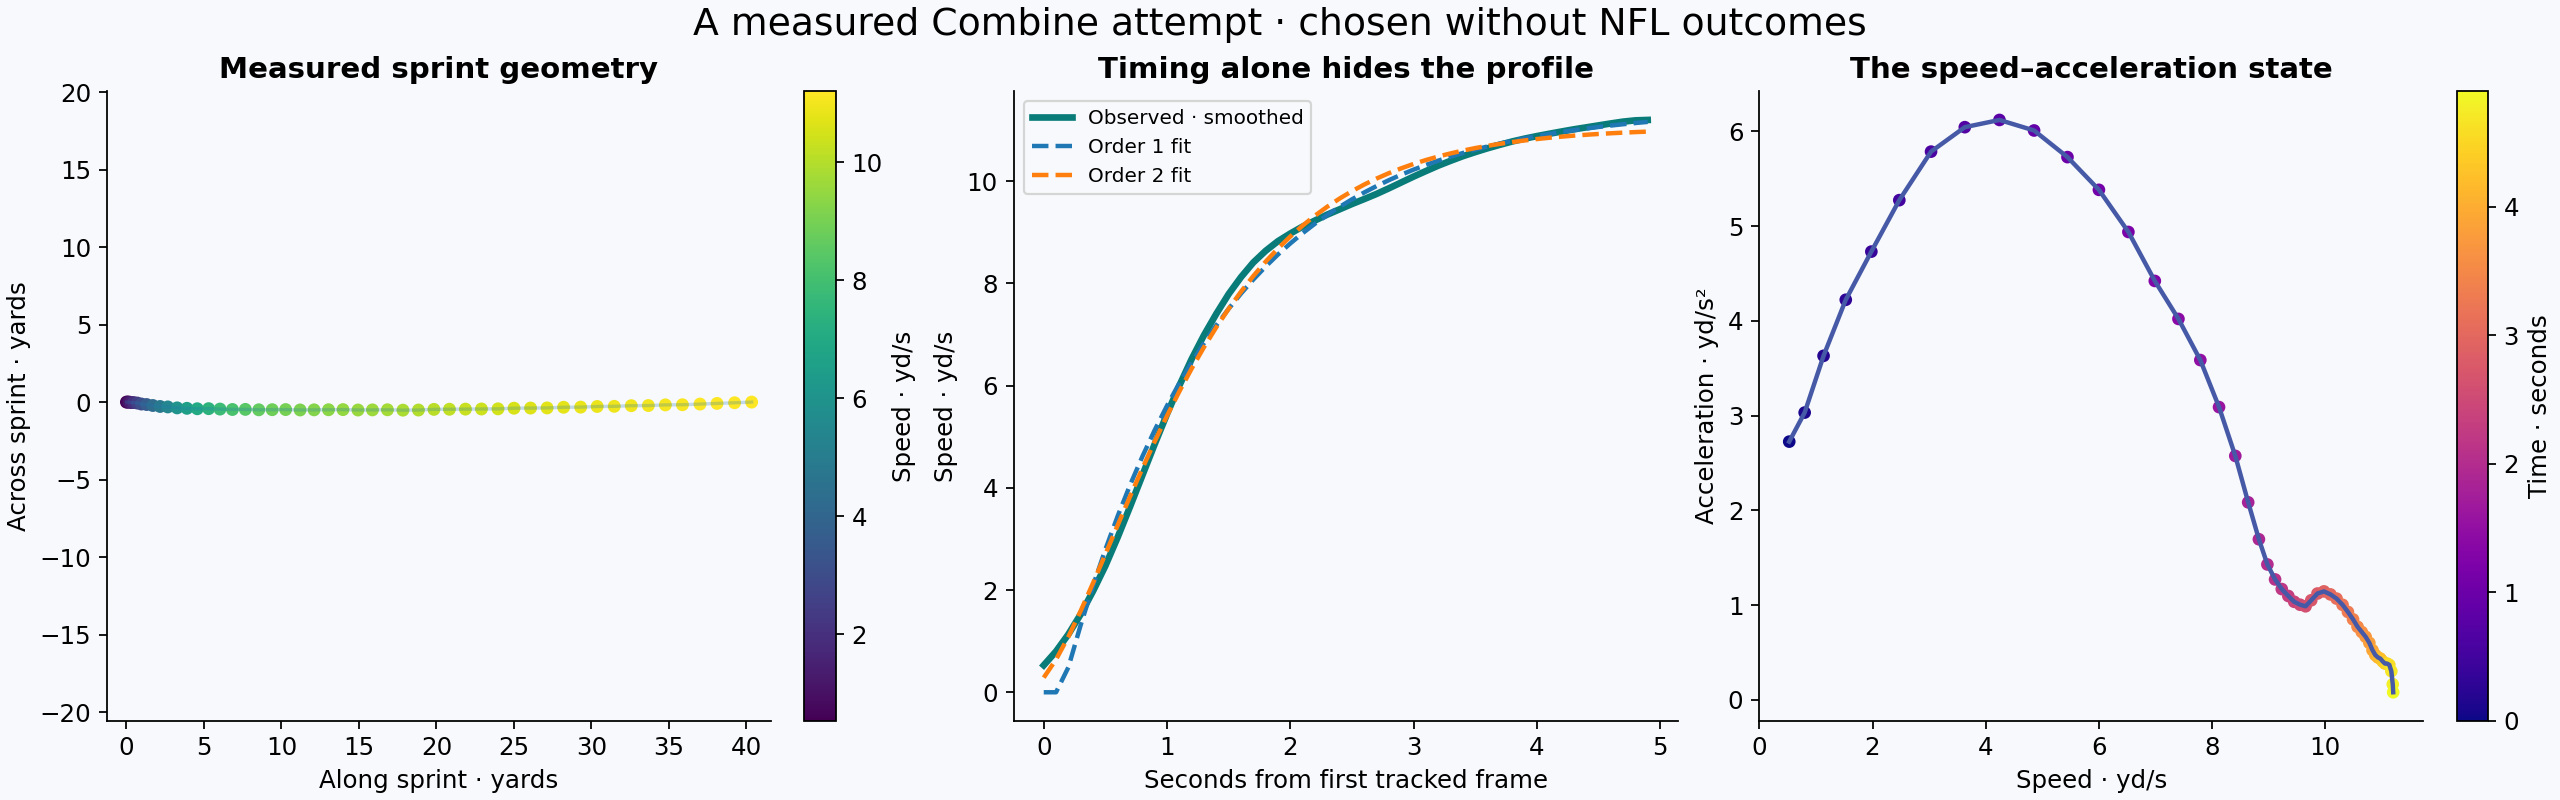

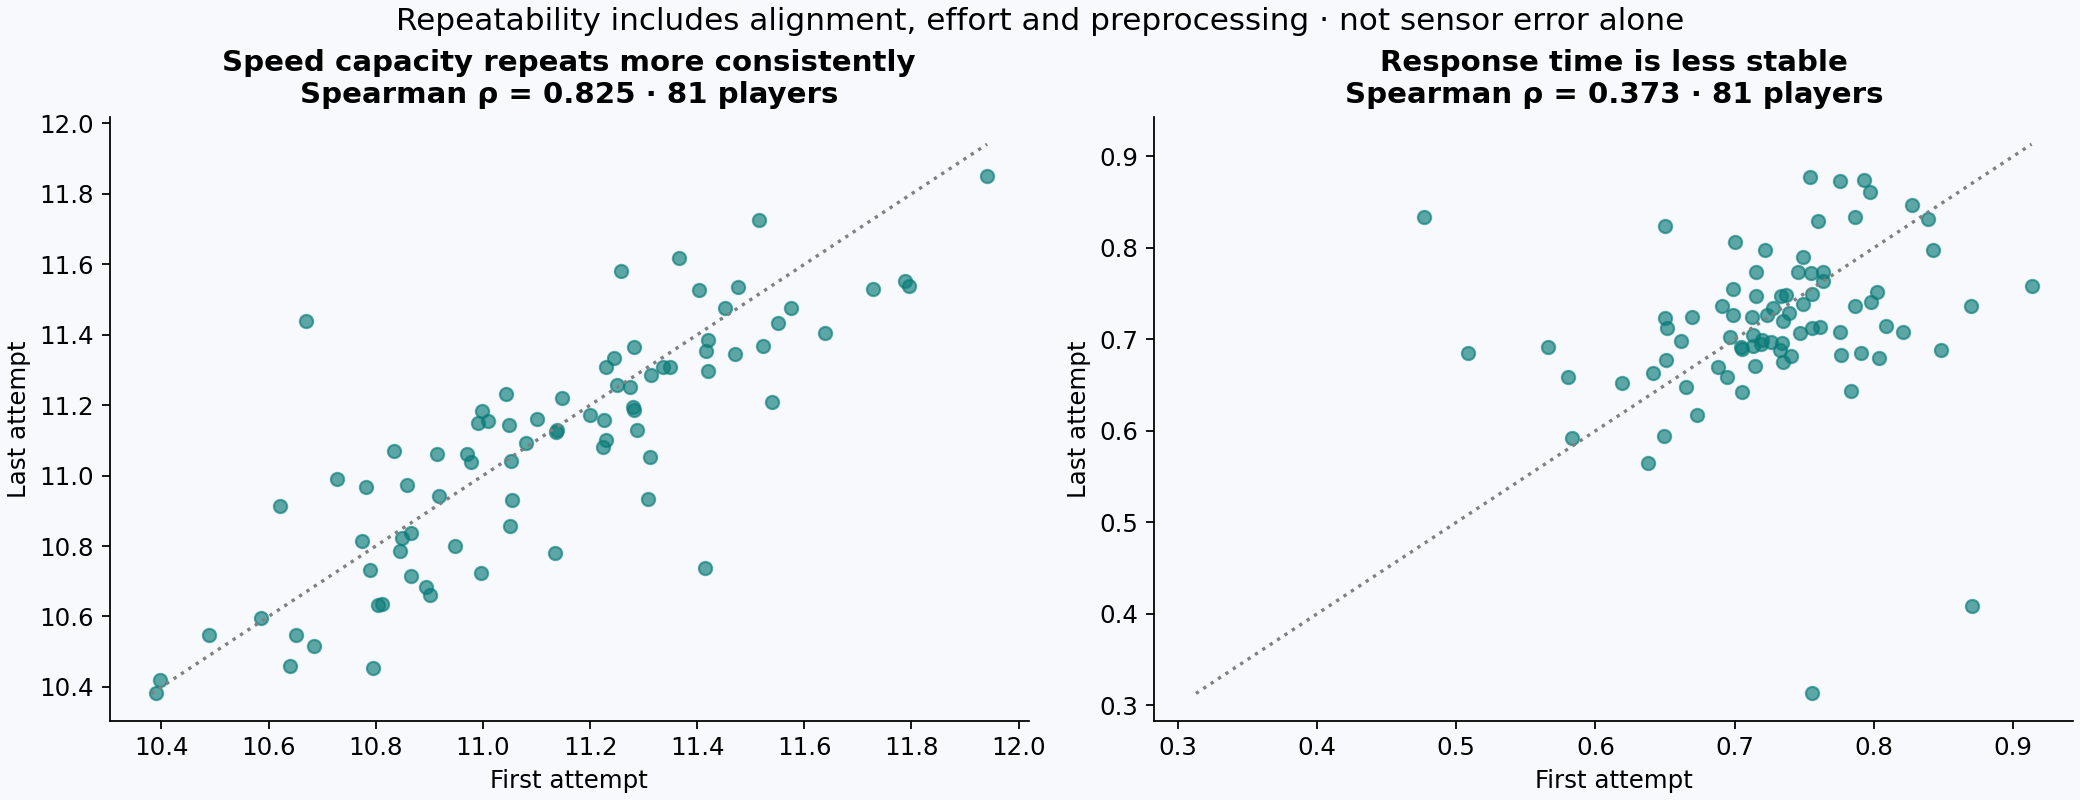

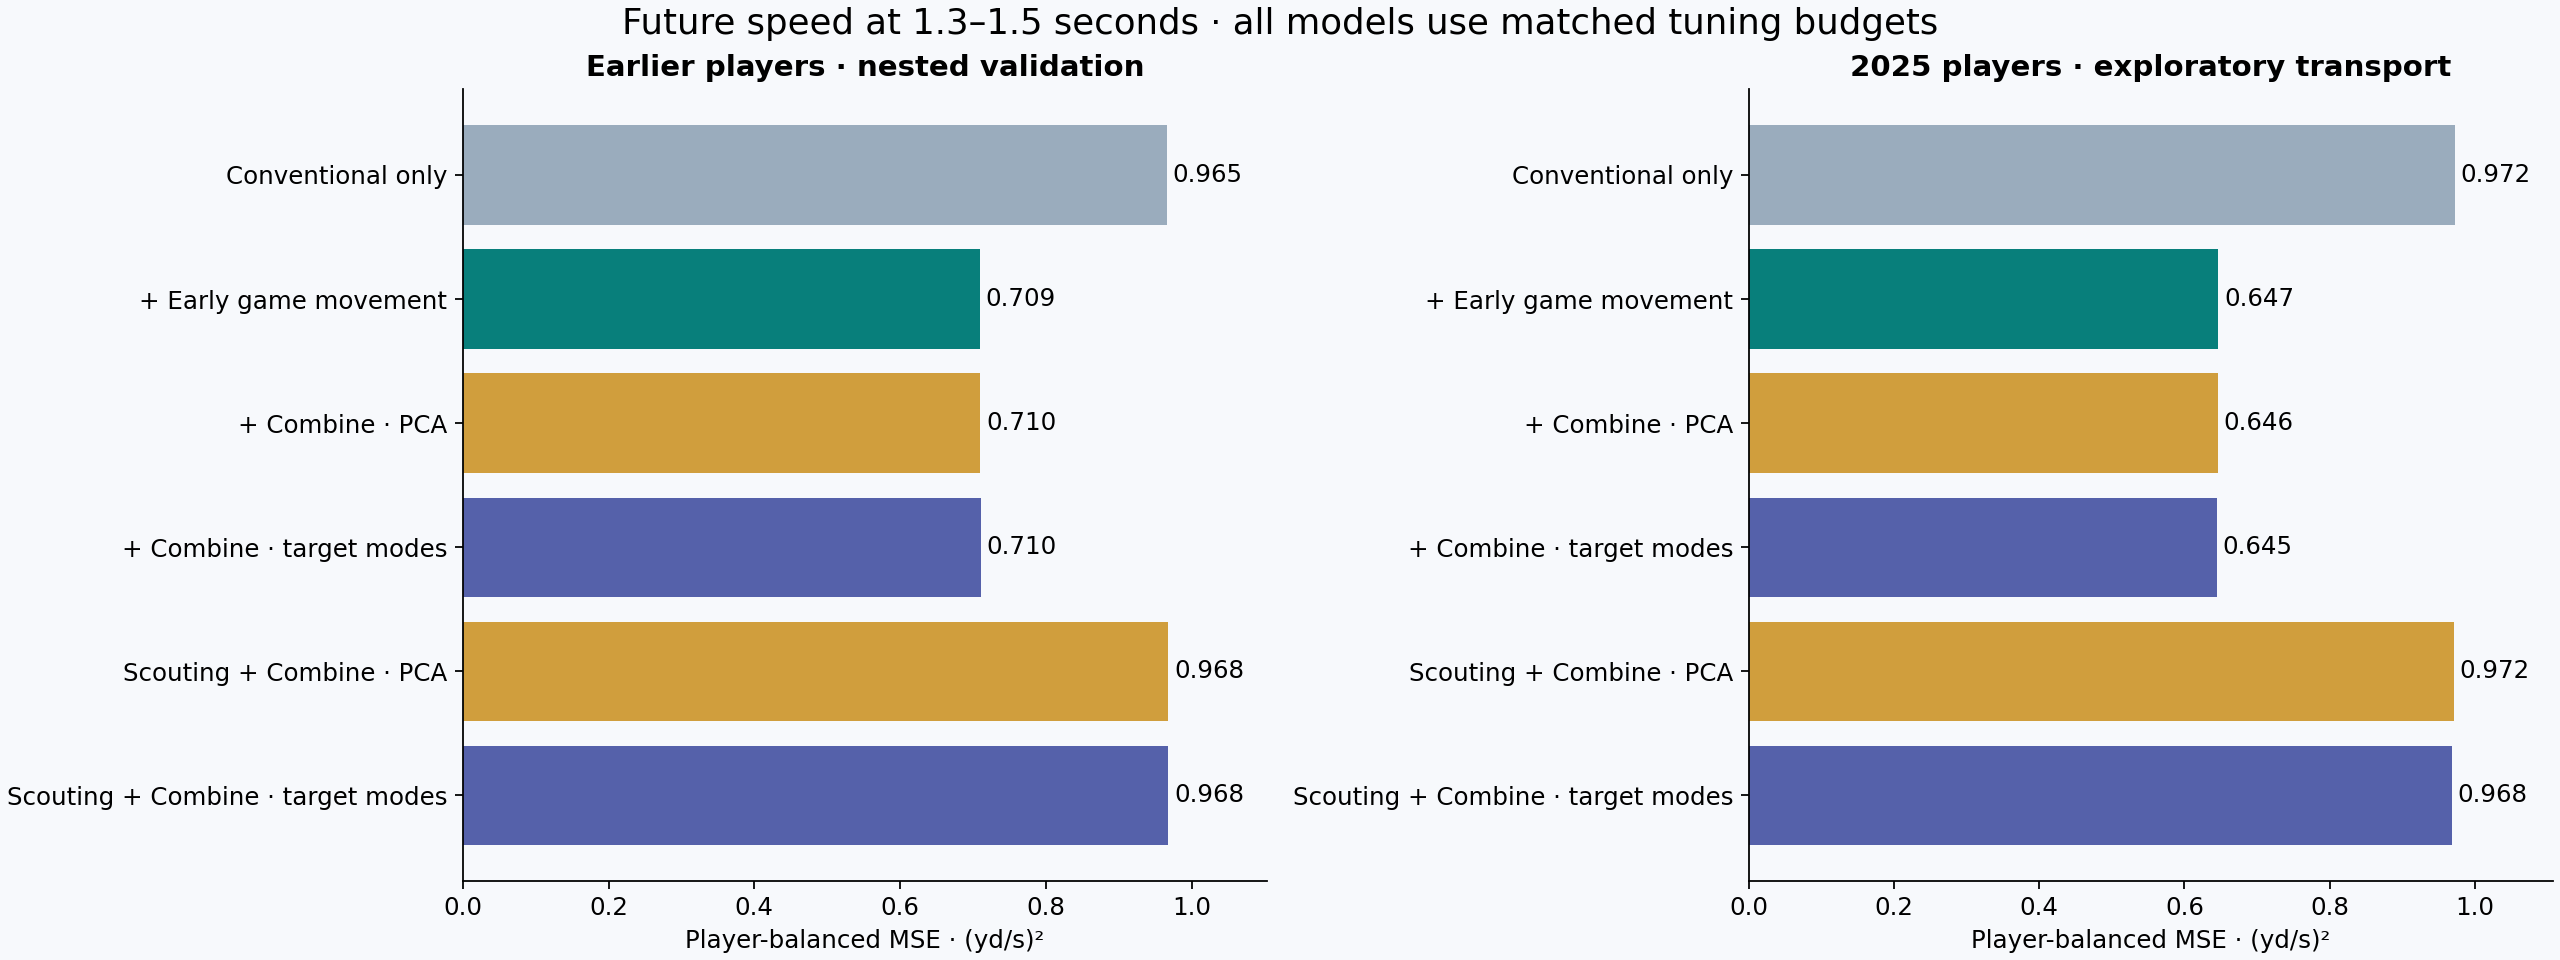

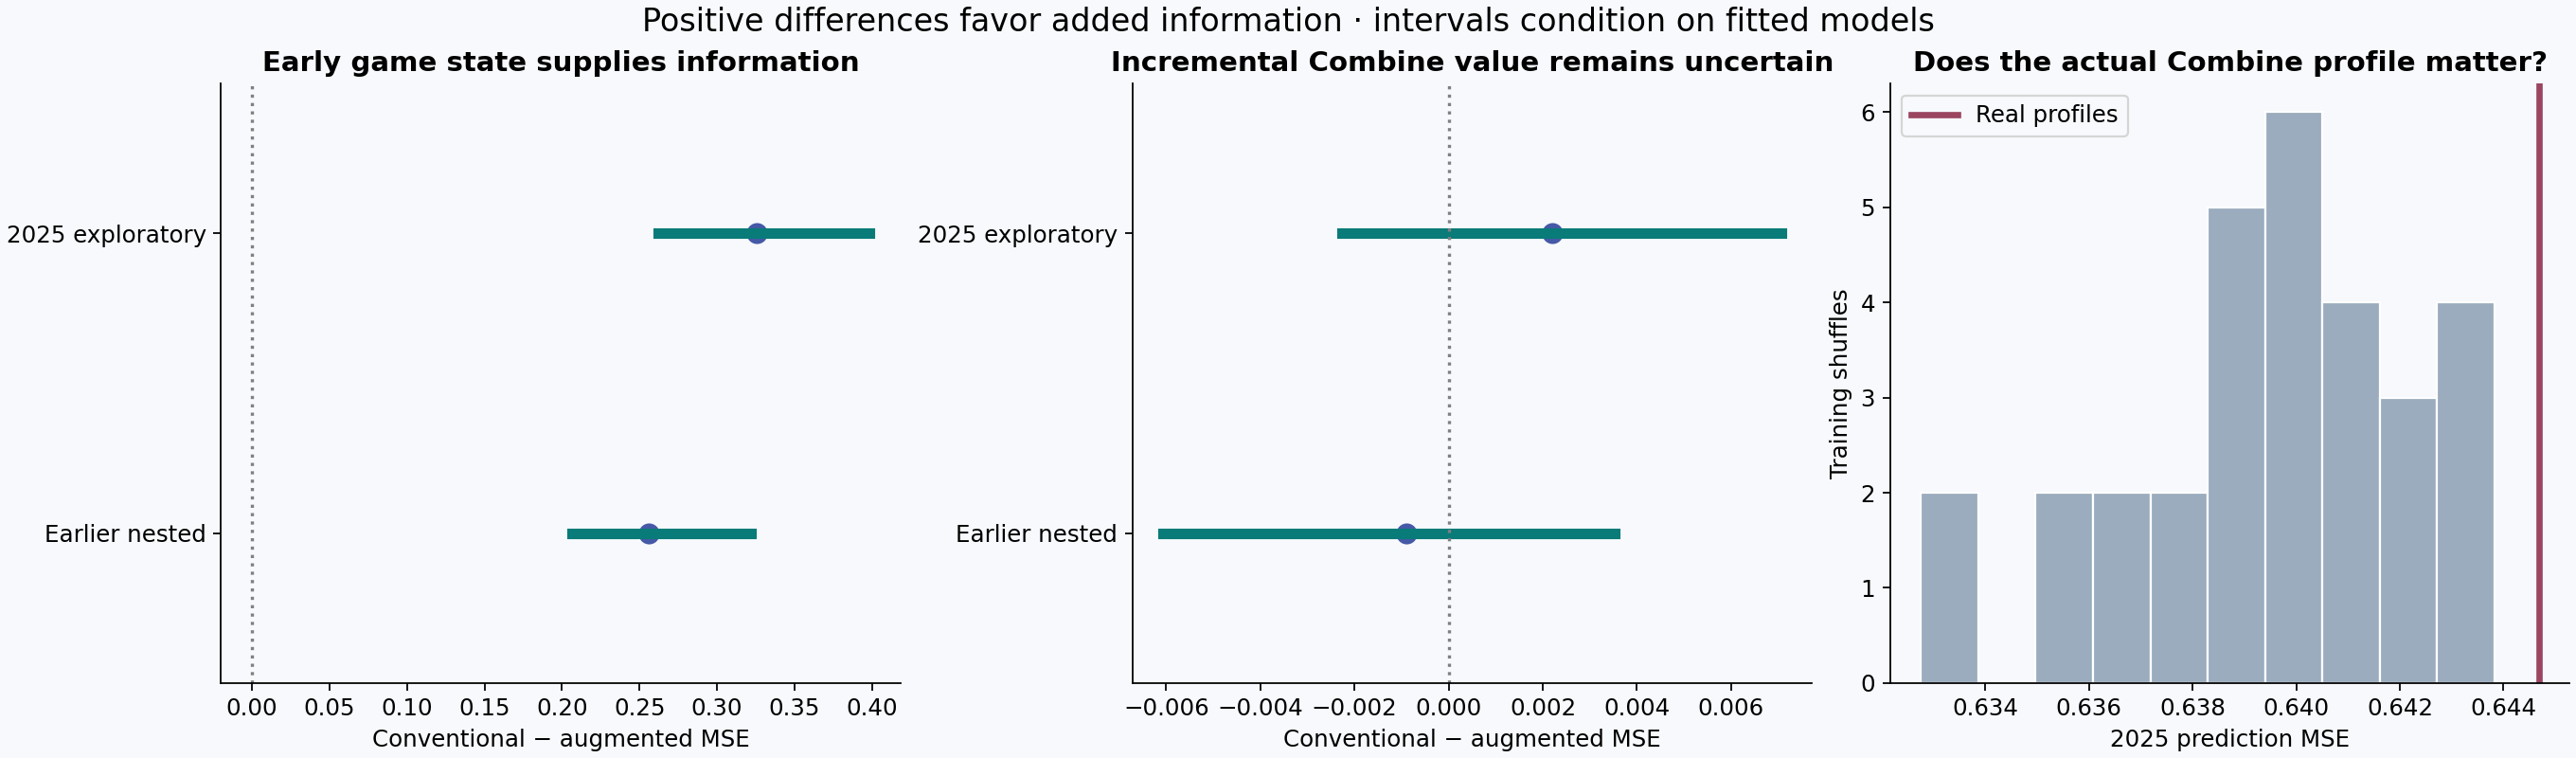

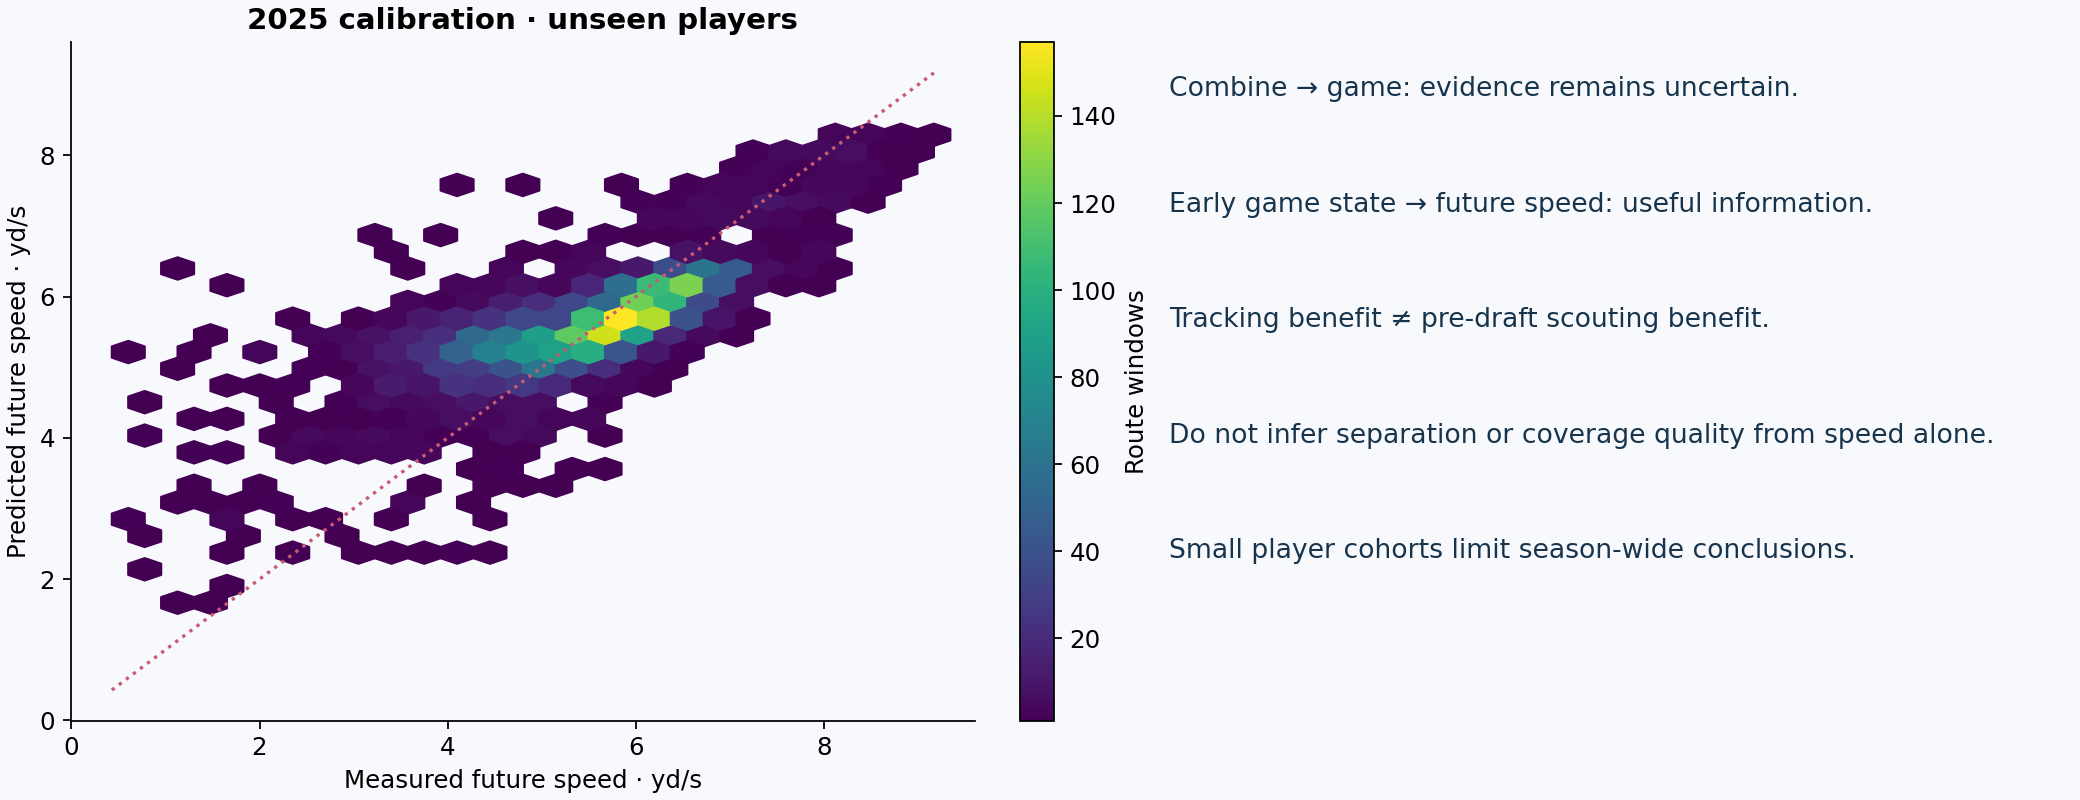

In [5]:
figures=V.run(OUT,OUT/'figures')
for figure in figures: display(Image(filename=str(figure)))
test=result['exploratory_2025']; baseline=test['mse']['conventional_without_state']; state=test['mse']['conventional_with_state']
print(f'Observed early-state relative MSE reduction: {100*(1-state/baseline):.2f}%')
print('Incremental Combine result:',test['comparisons']['target_motion_increment'])


## Why a movement history can help—and what exact algebra cannot prove

For a supplied two-state linear response, an instantaneous speed observation can hide acceleration. Exact target recovery requires the future target row to lie in the row span of the observation map. Two histories may resolve the hidden direction. The licensed PerfectPower rational calculus checks that finite algebra below; it does not prove that NFL movement follows the surrogate or that a learned model generalizes. This motivates a testable observation design, rather than importing an unrelated number-theory theorem as a football guarantee.


In [6]:
from fractions import Fraction as Q
import exact_linear as E
q=Q(869479,1000000)
transition=E.matrix([[q,q/10],[0,q]])
observation=E.matrix([[1,0]])
future=E.multiply(observation,transition)
print('One observation:',E.target_factor(observation,future))
history=E.matrix([observation[0],future[0]])
print('Two observations:',E.target_factor(history,E.multiply(future,transition)))
print('Exact only for the supplied rational surrogate; no real-athlete theorem claimed.')


One observation: {'status': 'AMBIGUOUS', 'invisible_vector': (Fraction(0, 1), Fraction(1, 1)), 'target_difference': (Fraction(869479, 10000000),), 'execution_verified': False, 'field': 'Q'}
Two observations: {'status': 'EXACT_TARGET_FACTOR', 'decoder': ((Fraction(-755993731441, 1000000000000), Fraction(869479, 500000)),), 'execution_verified': False, 'field': 'Q'}
Exact only for the supplied rational surrogate; no real-athlete theorem claimed.


## Findings and boundaries

The completed reconstruction reduces future-speed MSE from 0.97226 to 0.64689 in eighteen 2025 receivers when early game state is observed: 33.47%. Earlier-player nested validation improves by 26.52%. The 2025 state-channel difference interval is [0.26236, 0.39855], and team-cluster resampling remains positive. This demonstrates information in the recorded game-state channel, not an added pre-draft Combine advantage. The incremental target-conditioned Combine difference is only 0.00220, with interval [−0.00226, 0.00707]; earlier nested prediction worsens slightly. Shuffled training profiles have lower average test MSE than the real profiles. Across eighty-one repeat participants, fitted capacity has rank correlation 0.825, but response time only 0.373. These results keep the scouting hypothesis uncertain. Faster subsequent movement also does not automatically mean better separation, coverage, or team outcomes. The retained historical receiver-separation study and defensive-back transition study did not establish a scouting improvement; their aggregate record is preserved separately and those studies are not rerun by this notebook.

Our contribution is the distinction between a measurable motion signature, a repeatable player characteristic, and a transferable predictive variable. Coaches can use the geometric views to inspect acceleration strategies; scouts should require stable, out-of-player evidence before assigning draft value. Small cohorts, conditional play availability, shared team effects, charted context, and prior test inspection limit broad claims. Future validation must use a genuinely new class or independently held-out target and a frozen protocol.

Official sources: [competition data](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data), [rules](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/rules). Competition data and private player-level outputs are excluded from the distributed package; notebook intermediates stay outside public output directories. No integration with the betting application, public Kaggle publication, or formal entry is implied by local execution. Source modules and source hashes are embedded above; pinned local dependencies are supplied in the package.
